# TEAM 05 · 센서 입력 확장 모델 성능 평가

원본 `최최종코드.ipynb`의 STEP 0~5 코드를 그대로 쓰고 **입력 변수만 바꾼 버전**입니다. 알고리즘, 하이퍼파라미터, 시간순 분할, Top-k 선택, 최종 모델 선택 규칙은 원본과 같습니다. 바꾼 곳은 코드에 `# [수정]`으로 표시했습니다.

| 구분 | 원본 (As-Is) | 이 노트북 (To-Be) |
|---|---|---|
| 입력 변수 | 계획 7개 | 계획 7개 + **공정 센서·이벤트 12개** = 19개 |
| 파생 변수 | 계획 파생 4개 | 계획 파생 4개 + **공정 파생 5개** |
| 제외 변수 | — | `actual_qty`(Blind 입력에 없음), `actual_lead_time_min`·`schedule_delay_min`·`on_time_completion_flag`·`bottleneck_station`(정답·사후 정보) |

- **공정 센서 12개**: 공정 A~D 사이클, B·C·D 앞 대기, 시작·종료 WIP, 교체·설비 정지·자재 대기 시간
- **공정 파생 5개**: 최대 사이클, 병목 처리시간(최대 사이클 × 계획 수량), 대기 합계, 이벤트 합계(교체 + 정지 + 자재), WIP 증감
- **예측 시점**: 계획 시점이 아니라 **공정 진행 중(센서값 수집 후)** 재예측이다. 계획 시점 모델(As-Is)과의 비교는 마지막 **STEP 6**에 있다.

**실행 방법 (Colab)**: 실행하면 CSV 3개(원본 생산 데이터, Blind 입력, Blind 정답)를 업로드하라고 나온다. 로컬에서는 환경변수 `TEAM3_DATA_DIR`에 세 파일이 있는 폴더를 지정한다.

In [5]:
# ============================================================
# TEAM 3 | 생산 지연 4등급 예측 + 3단계 피처 개선
# Google Colab 한 셀 실행용 최종 코드
#
# STEP 0 : 데이터 업로드 / 시간순 분할
# STEP 1 : 데이터 프로파일링 + 기본 모델
# STEP 2 : 변수 중요도 + Top 5/7 + SHAP
# STEP 3 : 파생변수 + PCA
# STEP 4 : 단계별 성능 + ROC/AUC + 3구간 검증
# STEP 5 : Blind 평가 + 입력 민감도 + 오예측 분석
#
# CatBoost 제외 / 기존 그래프 및 히트맵 유지
# ============================================================

In [6]:
# ============================================================
# STEP 0-1. 라이브러리 및 Colab 환경 설정
# ============================================================

import os
import sys
import glob
import io
import zipfile
import subprocess
import importlib
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.inspection import permutation_importance
from sklearn import set_config
set_config(display="text")  # [수정] Windows 로컬에서 모델 HTML 표시 인코딩 오류 방지
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    average_precision_score,
    precision_recall_curve,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

# 필요한 라이브러리만 자동 설치
for pkg in ["lightgbm", "shap"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip",
            "install", "-q", pkg
        ])

import lightgbm as lgb
import shap

warnings.filterwarnings(
    "ignore",
    message="X does not have valid feature names"
)

SEED = 42

OUT = Path("team3_results")
OUT.mkdir(exist_ok=True)

NAMES = [
    "Normal", "Attention",
    "Warning", "Failure"
]

COLORS = [
    "#42ac9c", "#e0bc59",
    "#ec9a5d", "#ce6868"
]

CAT = [
    "shift",
    "line_id",
    "product_family",
    "order_priority"
]

NUM = [
    "planned_qty",
    "available_operators",
    "planned_lead_time_min",

    # [수정] 공정 센서·이벤트 12개 (Blind 입력에도 존재)
    "changeover_min",
    "station_a_cycle_sec",
    "station_b_cycle_sec",
    "station_c_cycle_sec",
    "station_d_cycle_sec",
    "wait_before_b_min",
    "wait_before_c_min",
    "wait_before_d_min",
    "wip_start_qty",
    "wip_end_qty",
    "equipment_stop_min",
    "material_wait_min"
]

BASE = CAT + NUM

DERIVED = [
    "qty_per_operator",
    "qty_per_min",
    "min_per_qty",
    "operator_min_per_qty",

    # [수정] 공정 파생 5개
    "max_cycle_sec",
    "bottleneck_proc_min",
    "total_wait_min",
    "event_total_min",
    "wip_delta"
]

EXT = BASE + DERIVED

# CatBoost 제외
ALGORITHMS = [
    "Dummy",
    "LogisticRegression",
    "RandomForest",
    "HistGradientBoosting",
    "LightGBM"
]

In [7]:
# ============================================================
# STEP 0-2. 한글 폰트 및 그래프 출력 설정
# ============================================================

font_paths = glob.glob(
    "/usr/share/fonts/**/*Nanum*.ttf",
    recursive=True
)

if not font_paths and "google.colab" in sys.modules:

    subprocess.run(
        [
            "apt-get", "-qq",
            "install", "-y", "fonts-nanum"
        ],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
        check=False
    )

    font_paths = glob.glob(
        "/usr/share/fonts/**/*Nanum*.ttf",
        recursive=True
    )

for path in font_paths:
    fm.fontManager.addfont(path)

if font_paths:

    font = next(
        (
            p for p in font_paths
            if p.endswith("/NanumBarunGothic.ttf")
        ),
        next(
            (
                p for p in font_paths
                if p.endswith("/NanumGothic.ttf")
            ),
            font_paths[0]
        )
    )

    plt.rcParams["font.family"] = (
        fm.FontProperties(fname=font).get_name()
    )

# [수정] 로컬 Windows 실행 시 한글 폰트
if not font_paths and sys.platform.startswith("win"):
    plt.rcParams["font.family"] = "Malgun Gothic"

plt.rcParams.update({
    "axes.unicode_minus": False,
    "figure.dpi": 105
})


# ============================================================
# 공통 그래프 출력 및 히트맵 함수
# ============================================================

def show_fig(filename):
    """그래프를 Colab 화면에 출력하고 PNG로 저장"""

    plt.tight_layout()

    plt.savefig(
        OUT / f"{filename}.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


def heatmap(
    ax, df, title,
    cmap="YlGnBu",
    fmt=".2f",
    vmin=None,
    vmax=None
):
    """상관관계·성능표·오예측 공통 히트맵"""

    z = df.to_numpy(dtype=float)

    im = ax.imshow(
        z,
        cmap=cmap,
        aspect="auto",
        vmin=vmin,
        vmax=vmax
    )

    ax.set(
        xticks=np.arange(len(df.columns)),
        yticks=np.arange(len(df.index)),
        title=title
    )

    ax.set_xticklabels(
        df.columns,
        rotation=40,
        ha="right",
        fontsize=9
    )

    ax.set_yticklabels(
        df.index,
        fontsize=9
    )

    for (r, c), value in np.ndenumerate(z):

        if np.isfinite(value):

            ax.text(
                c, r,
                f"{value:{fmt}}",
                ha="center",
                va="center",
                fontsize=8
            )

    return im

In [8]:
# ============================================================
# STEP 0-3. CSV 파일 3개 불러오기
# ============================================================

def find_csvs(folder):

    result = {}

    for path in Path(folder).glob("*.csv"):

        try:
            cols = set(
                pd.read_csv(
                    path,
                    nrows=1,
                    encoding="utf-8-sig"
                ).columns
            )

            if {
                "record_id",
                "schedule_delay_min",
                "lot_start_time"
            } <= cols:

                result["train"] = path

            elif {
                "record_id",
                "actual_schedule_delay_min"
            } <= cols:

                result["answer"] = path

            elif {
                "record_id",
                "planned_lead_time_min",
                "lot_start_time"
            } <= cols:

                result["blind"] = path

        except Exception:
            continue

    return result


# [수정] Colab이 아니면 로컬 폴더에서 CSV 3개를 찾는다
IN_COLAB = "google.colab" in sys.modules

candidates = [
    os.environ.get("TEAM3_DATA_DIR"),
    "/content",
    ".",
    "data",
    "review_exp/nb_runs/data",
    Path.home() / "Documents" / "카카오톡 받은 파일",
    Path.home() / "Downloads",
]

folder, sources = None, {}

for c in candidates:
    if c and Path(c).is_dir():
        found = find_csvs(Path(c))
        # 원본·Blind 입력·Blind 정답이 서로 다른 폴더에 있어도 합친다
        for k, v in found.items():
            sources.setdefault(k, v)
        if folder is None and found:
            folder = Path(c)
    if len(sources) == 3:
        break

if folder is None:
    folder = Path("/content") if IN_COLAB else Path(".")

print("CSV 탐색 결과:", {k: str(v) for k, v in sources.items()})

if len(sources) != 3 and IN_COLAB:

    from google.colab import files

    print("CSV 데이터 3개를 업로드하세요.")
    print("① 원본 생산 데이터 1600건")
    print("② Blind 입력 데이터 1600건")
    print("③ Blind 정답 데이터 1600건")
    print("ZIP 파일 업로드도 가능합니다.")

    uploaded = files.upload()

    for filename, content in uploaded.items():

        if filename.lower().endswith(".zip"):

            with zipfile.ZipFile(
                io.BytesIO(content)
            ) as z:

                for name in z.namelist():

                    if (
                        name.lower().endswith(".csv")
                        and not name.endswith("/")
                    ):

                        (
                            folder / Path(name).name
                        ).write_bytes(
                            z.read(name)
                        )

    sources = find_csvs(folder)

if set(sources) != {
    "train", "blind", "answer"
}:

    raise ValueError(
        f"CSV 3종이 필요합니다. "
        f"발견한 유형: {list(sources)}. "
        f"로컬에서는 원본·Blind 입력·Blind 정답 CSV를 노트북과 같은 폴더(또는 data 폴더)에 두거나 "
        f"환경변수 TEAM3_DATA_DIR로 폴더를 지정하세요."
    )


original = pd.read_csv(
    sources["train"],
    encoding="utf-8-sig"
)

blind_input = pd.read_csv(
    sources["blind"],
    encoding="utf-8-sig"
)

answer = pd.read_csv(
    sources["answer"],
    encoding="utf-8-sig"
)

assert (
    len(original)
    == len(blind_input)
    == len(answer)
    == 1600
)

assert all(
    d.record_id.is_unique
    for d in [
        original,
        blind_input,
        answer
    ]
)

blind = blind_input.merge(
    answer,
    on="record_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert blind["_merge"].eq("both").all()

blind = blind.drop(
    columns="_merge"
)

CSV 탐색 결과: {'train': 'team3_flow.csv', 'answer': 'review_exp\\nb_runs\\data\\answer_key_team5.csv', 'blind': 'review_exp\\nb_runs\\data\\blind_input_team5_v02.csv'}


In [9]:
# ============================================================
# STEP 0-4. 목표변수 생성 및 시간순 분할
# ============================================================

# 0 Normal    : 18분 미만
# 1 Attention : 18~35분 미만
# 2 Warning   : 35~60분 미만
# 3 Failure   : 60분 이상

def target(delay):

    s = pd.to_numeric(
        delay,
        errors="raise"
    )

    if s.isna().any():
        raise ValueError(
            "지연시간 정답에 결측이 있습니다."
        )

    return np.select(
        [
            s < 18,
            s < 35,
            s < 60
        ],
        [0, 1, 2],
        default=3
    ).astype(int)


def temporal_split(df, fraction=0.75):
    """
    시간순 분할 함수

    1. 동일 시작 시각 로트를 양쪽에 나누지 않음
    2. 검증 시작 시점 이전에 완료된 것으로
       추정되는 로트만 학습에 사용
    3. 실제 리드타임은 학습 입력 X로 사용하지 않음
    """

    ordered = df.sort_values(
        [
            "lot_start_time",
            "record_id"
        ]
    ).reset_index(drop=True)

    cutoff = ordered.iloc[
        int(len(ordered) * fraction)
    ]["lot_start_time"]

    older = ordered[
        ordered.lot_start_time < cutoff
    ].copy()

    future = ordered[
        ordered.lot_start_time >= cutoff
    ].copy()

    completed_at = (
        older.lot_start_time
        + pd.to_timedelta(
            older.actual_lead_time_min,
            unit="m"
        )
    )

    usable = older[
        completed_at <= cutoff
    ].copy()

    excluded = len(older) - len(usable)

    return (
        usable,
        future,
        cutoff,
        excluded
    )


original["y"] = target(
    original["schedule_delay_min"]
)

blind["y"] = target(
    blind["actual_schedule_delay_min"]
)

original["lot_start_time"] = pd.to_datetime(
    original["lot_start_time"]
)

chron = original.sort_values(
    [
        "lot_start_time",
        "record_id"
    ]
).reset_index(drop=True)

train, valid, cutoff, excluded = (
    temporal_split(chron, 0.75)
)

y_train = train.y.to_numpy()
y_valid = valid.y.to_numpy()
y_blind = blind.y.to_numpy()

print("\n[STEP 0] 데이터 분할")
print("학습:", len(train))
print("검증:", len(valid))
print("Blind:", len(blind))
print("분할 경계:", cutoff)
print("정답 미확정 추정 제외:", excluded)
print("모델 입력변수:", BASE)


[STEP 0] 데이터 분할
학습: 1197
검증: 401
Blind: 1600
분할 경계: 2026-09-14 00:00:00
정답 미확정 추정 제외: 2
모델 입력변수: ['shift', 'line_id', 'product_family', 'order_priority', 'planned_qty', 'available_operators', 'planned_lead_time_min', 'changeover_min', 'station_a_cycle_sec', 'station_b_cycle_sec', 'station_c_cycle_sec', 'station_d_cycle_sec', 'wait_before_b_min', 'wait_before_c_min', 'wait_before_d_min', 'wip_start_qty', 'wip_end_qty', 'equipment_stop_min', 'material_wait_min']


In [10]:
# ============================================================
# STEP 0-5. 파생변수 생성
# ============================================================

def enrich(df):

    d = df.copy()

    q = pd.to_numeric(
        d.planned_qty,
        errors="coerce"
    )

    op = pd.to_numeric(
        d.available_operators,
        errors="coerce"
    )

    lead = pd.to_numeric(
        d.planned_lead_time_min,
        errors="coerce"
    )

    d["qty_per_operator"] = (
        q / op.where(op > 0)
    )

    d["qty_per_min"] = (
        q / lead.where(lead > 0)
    )

    d["min_per_qty"] = (
        lead / q.where(q > 0)
    )

    d["operator_min_per_qty"] = (
        op * lead / q.where(q > 0)
    )

    # [수정] 공정 파생변수
    cycles = d[[
        "station_a_cycle_sec",
        "station_b_cycle_sec",
        "station_c_cycle_sec",
        "station_d_cycle_sec"
    ]]

    d["max_cycle_sec"] = cycles.max(axis=1)                  # 가장 느린 공정 사이클
    d["bottleneck_proc_min"] = d["max_cycle_sec"] * q / 60   # 병목 공정 처리시간(분)

    d["total_wait_min"] = d[[
        "wait_before_b_min",
        "wait_before_c_min",
        "wait_before_d_min"
    ]].sum(axis=1, min_count=1)                              # 공정 앞 대기 합계

    d["event_total_min"] = (
        d["changeover_min"]
        + d["equipment_stop_min"]
        + d["material_wait_min"]
    )                                                        # 교체·정지·자재 이벤트 합계

    d["wip_delta"] = d["wip_end_qty"] - d["wip_start_qty"]   # WIP 증감

    d[DERIVED] = d[DERIVED].replace(
        [np.inf, -np.inf],
        np.nan
    )

    return d


train_ex = enrich(train)
valid_ex = enrich(valid)

In [11]:
# ============================================================
# STEP 1. 데이터 프로파일링
# ============================================================

print("\n========== STEP 1. 데이터 분석 ==========")

profile = pd.DataFrame({

    "자료형":
        original.dtypes.astype(str),

    "결측수":
        original.isna().sum(),

    "결측률(%)":
        original.isna().mean() * 100,

    "고유값수":
        original.nunique()

})

display(profile.round(2))

profile.to_csv(
    OUT / "01_profile.csv",
    encoding="utf-8-sig"
)

display(
    train[
        NUM + ["schedule_delay_min"]
    ].describe().T.round(2)
)


========== STEP 1. 데이터 분석 ==========


,자료형,결측수,결측률(%),고유값수
record_id,object,0,0.00,1600
lot_start_time,datetime64[ns],0,0.00,1501
shift,object,0,0.00,2
line_id,object,0,0.00,3
product_family,object,0,0.00,3
order_priority,object,0,0.00,2
planned_qty,int64,0,0.00,157
actual_qty,int64,0,0.00,150
available_operators,int64,0,0.00,8
changeover_min,float64,0,0.00,188


,count,mean,std,min,25%,50%,75%,max
planned_qty,1197.0,179.31,31.33,100.0,158.0,179.0,201.0,270.0
available_operators,1197.0,8.56,1.49,5.0,8.0,9.0,10.0,12.0
planned_lead_time_min,1197.0,209.10,18.36,149.4,197.0,209.3,221.5,279.5
changeover_min,1197.0,5.08,10.33,0.0,0.0,0.0,0.0,42.6
station_a_cycle_sec,1197.0,45.26,3.54,34.3,42.8,45.1,47.7,55.9
station_b_cycle_sec,1197.0,49.00,4.18,35.8,46.2,49.0,51.7,65.3
station_c_cycle_sec,1192.0,48.63,5.60,33.5,44.6,48.4,52.6,66.0
station_d_cycle_sec,1197.0,43.14,2.95,32.9,41.2,43.2,45.0,53.8
wait_before_b_min,1197.0,13.23,7.69,0.0,7.8,12.4,18.4,38.6
wait_before_c_min,1189.0,12.07,8.15,0.0,6.4,11.1,16.6,44.8


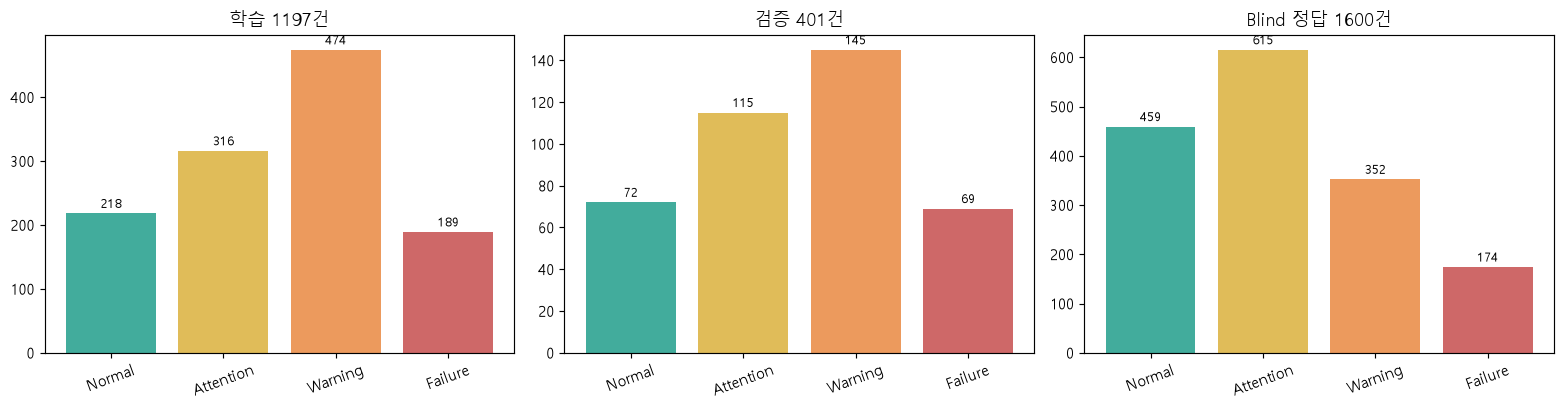

In [12]:
# ============================================================
# 그래프 01. 목표 위험등급 분포
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

datasets = [
    (
        train,
        f"학습 {len(train)}건"
    ),
    (
        valid,
        f"검증 {len(valid)}건"
    ),
    (
        blind,
        "Blind 정답 1600건"
    )
]

for ax, (df, title) in zip(
    axes, datasets
):

    counts = (
        df.y.value_counts()
        .reindex(
            range(4),
            fill_value=0
        )
    )

    bars = ax.bar(
        NAMES,
        counts,
        color=COLORS
    )

    ax.set_title(title)

    ax.tick_params(
        axis="x",
        rotation=20
    )

    ax.bar_label(
        bars,
        padding=2,
        fontsize=9
    )

show_fig("01_target_distribution")

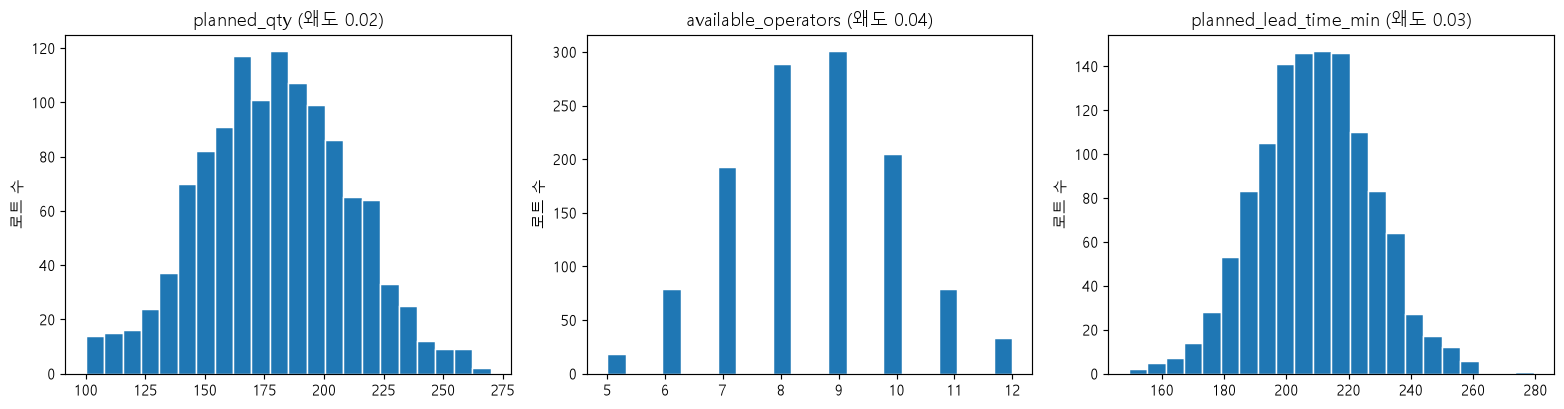

In [13]:
# ============================================================
# 그래프 02. 수치형 변수 분포
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for ax, col in zip(
    axes, NUM
):

    ax.hist(
        train[col].dropna(),
        bins=22,
        edgecolor="white"
    )

    ax.set_title(
        f"{col} (왜도 {train[col].skew():.2f})"
    )

    ax.set_ylabel(
        "로트 수"
    )

show_fig("02_numeric_histograms")

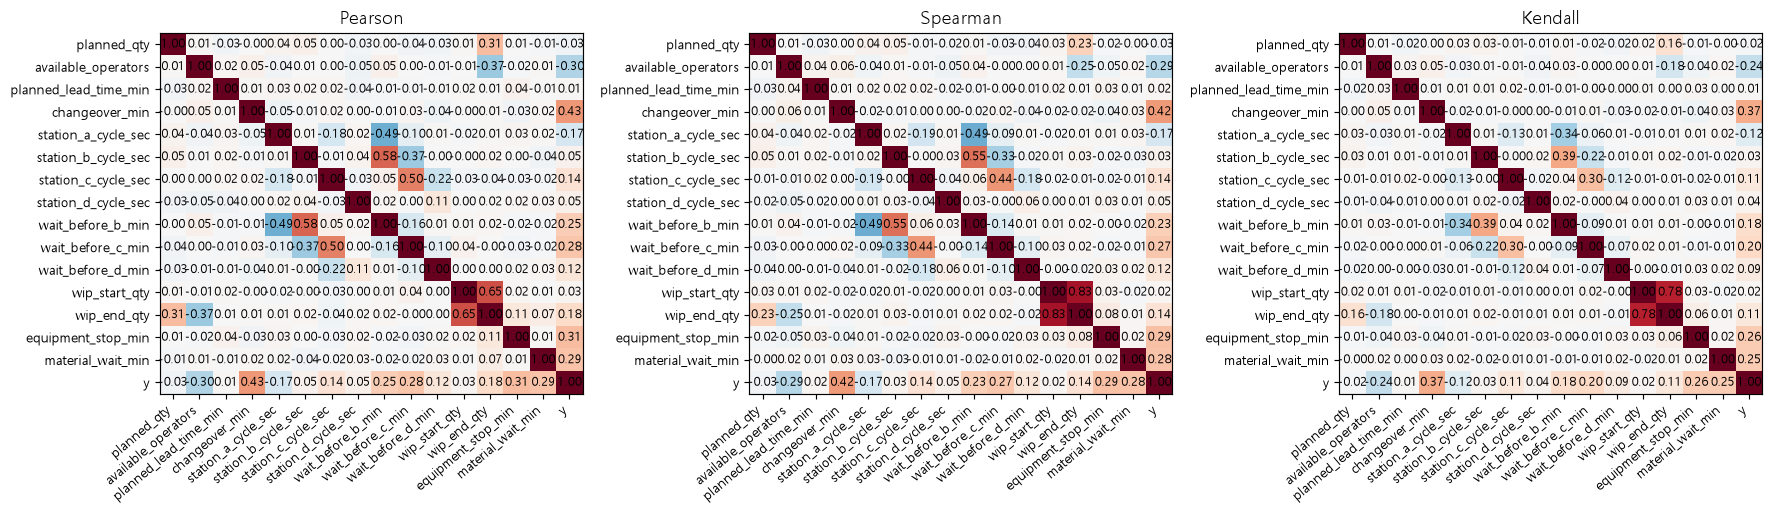

In [14]:
# ============================================================
# 히트맵 03. Pearson / Spearman / Kendall
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, method in zip(
    axes,
    [
        "pearson",
        "spearman",
        "kendall"
    ]
):

    corr = train[
        NUM + ["y"]
    ].corr(method=method)

    heatmap(
        ax,
        corr,
        method.title(),
        "RdBu_r",
        ".2f",
        -1,
        1
    )

show_fig("03_correlations")

In [15]:
# ============================================================
# STEP 1-2. 모델 생성 및 공통 평가 함수
# ============================================================

def estimator(alg):

    models = {

        "Dummy":
            lambda: DummyClassifier(
                strategy="most_frequent"
            ),

        "LogisticRegression":
            lambda: LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=SEED
            ),

        "RandomForest":
            lambda: RandomForestClassifier(
                n_estimators=90,
                min_samples_leaf=3,
                class_weight="balanced_subsample",
                max_features="sqrt",
                n_jobs=-1,
                random_state=SEED
            ),

        "HistGradientBoosting":
            lambda: HistGradientBoostingClassifier(
                max_iter=120,
                learning_rate=0.06,
                max_leaf_nodes=9,
                l2_regularization=3,
                random_state=SEED
            ),

        "LightGBM":
            lambda: lgb.LGBMClassifier(
                n_estimators=150,
                num_leaves=7,
                learning_rate=0.05,
                reg_lambda=1,
                random_state=SEED,
                n_jobs=1,
                verbosity=-1
            )

    }

    return models[alg]()


def pipeline(cols, alg, pca=False):

    cat = [
        c for c in cols
        if c in CAT
    ]

    num = [
        c for c in cols
        if c not in CAT
    ]

    try:

        ohe = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:

        ohe = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    blocks = []

    if cat:

        blocks.append((
            "cat",

            Pipeline([
                (
                    "fill",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),
                (
                    "onehot",
                    ohe
                )
            ]),

            cat
        ))

    if num:

        blocks.append((
            "num",

            Pipeline([
                (
                    "fill",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "scale",
                    StandardScaler()
                )
            ]),

            num
        ))

    steps = [
        (
            "pre",

            ColumnTransformer(
                blocks,
                sparse_threshold=0
            )
        )
    ]

    if pca:

        steps.append((
            "pca",

            PCA(
                n_components=0.95,
                svd_solver="full"
            )
        ))

    steps.append((
        "model",
        estimator(alg)
    ))

    return Pipeline(steps)


def score(model, x, y):

    pred = model.predict(x)

    classes = list(
        model.classes_
    )

    if 3 in classes:

        p3 = model.predict_proba(x)[
            :,
            classes.index(3)
        ]

    else:

        p3 = np.zeros(len(pred))

    return {

        "accuracy":
            accuracy_score(y, pred),

        "macro_f1":
            f1_score(
                y,
                pred,
                average="macro",
                zero_division=0
            ),

        "failure_recall":
            recall_score(
                y == 3,
                pred == 3,
                zero_division=0
            ),

        "failure_precision":
            precision_score(
                y == 3,
                pred == 3,
                zero_division=0
            ),

        "failure_ap":
            average_precision_score(
                y == 3,
                p3
            ),

        "qwk":
            cohen_kappa_score(
                y,
                pred,
                weights="quadratic"
            )
    }


models = {}
configurations = {}
records = []


def fit_eval(
    key, cols, alg, pca=False
):
    """
    모델 학습 및 검증

    동일 모델 중복 학습 방지
    모델별 성능표 저장
    """

    if key not in models:

        cols = [
            c for c in EXT
            if c in cols
        ]

        m = pipeline(
            cols,
            alg,
            pca
        )

        m.fit(
            train_ex[cols],
            y_train
        )

        models[key] = m

        configurations[key] = (
            cols,
            alg,
            pca
        )

        result = score(
            m,
            valid_ex[cols],
            y_valid
        )

        records.append({

            "구성": key,
            "모델": alg,
            "변수수": len(cols),

            **result
        })

    return models[key]

In [16]:
# ============================================================
# STEP 1-3. 기본 모델 학습 및 비교
# ============================================================

for alg in ALGORITHMS:

    fit_eval(
        "기본_" + alg,
        BASE,
        alg
    )

base_scores = pd.DataFrame(
    records
).sort_values(
    "macro_f1",
    ascending=False
)

display(
    base_scores.round(4)
)

best_alg = next(
    a for a in base_scores.모델
    if a != "Dummy"
)

print(
    "기본 성능 최우수 알고리즘:",
    best_alg
)

,구성,모델,변수수,accuracy,macro_f1,failure_recall,failure_precision,failure_ap,qwk
1,기본_LogisticRegression,LogisticRegression,19,0.6209,0.6232,0.7246,0.7246,0.8238,0.7771
4,기본_LightGBM,LightGBM,19,0.5885,0.5786,0.5072,0.7292,0.7065,0.7260
2,기본_RandomForest,RandomForest,19,0.5810,0.5774,0.6232,0.6515,0.7005,0.7159
3,기본_HistGradientBoosting,HistGradientBoosting,19,0.5786,0.5704,0.5362,0.7115,0.7054,0.7162
0,기본_Dummy,Dummy,19,0.3616,0.1328,0.0000,0.0000,0.1721,0.0000


기본 성능 최우수 알고리즘: LogisticRegression


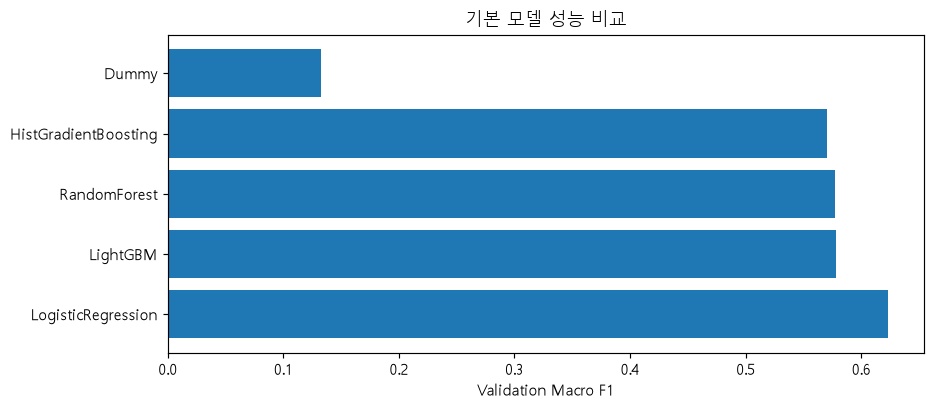

In [17]:
# ============================================================
# 그래프 04. 기본 모델 성능 비교
# ============================================================

plt.figure(figsize=(9, 4))

plt.barh(
    base_scores.모델,
    base_scores.macro_f1
)

plt.title(
    "기본 모델 성능 비교"
)

plt.xlabel(
    "Validation Macro F1"
)

show_fig("04_baseline_models")

In [18]:
# ============================================================
# STEP 2. Feature Importance 및 SHAP
# ============================================================

print(
    "\n========== STEP 2. 변수 중요도 =========="
)

# 중요도 계산도 시간순 내부 학습·검증으로 분리
inner_fit, inner_valid, inner_cutoff, inner_excluded = (
    temporal_split(train, 0.8)
)

inner_fit_ex = enrich(inner_fit)
inner_valid_ex = enrich(inner_valid)

print(
    "중요도 계산용 학습/검증:",
    len(inner_fit),
    len(inner_valid)
)


========== STEP 2. 변수 중요도 ==========
중요도 계산용 학습/검증: 955 240


In [19]:
# ============================================================
# STEP 2-1. Permutation Importance 함수
# ============================================================

def rank_features(cols):

    cols = [
        c for c in EXT
        if c in cols
    ]

    r = pipeline(
        cols,
        "RandomForest"
    )

    r.fit(
        inner_fit_ex[cols],
        inner_fit_ex.y
    )

    p = permutation_importance(
        r,
        inner_valid_ex[cols],
        inner_valid_ex.y,
        scoring="f1_macro",
        n_repeats=2,
        random_state=SEED,
        n_jobs=1
    )

    importance = pd.DataFrame({

        "variable": cols,

        "importance":
            p.importances_mean

    }).sort_values(
        "importance",
        ascending=False
    )

    return importance

In [20]:
# ============================================================
# STEP 2-2. SHAP 분석 공통 함수
# ============================================================

def plot_shap_rf(
    cols,
    filename,
    heading,
    sample_limit=120
):
    """
    RandomForest SHAP 계산

    Failure(3) 예측에 대한 변수 기여도 분석
    원핫 인코딩된 범주형 열을 원본 변수로 집계
    Blind 정답은 중요도 계산에 사용하지 않음
    """

    cols = [
        c for c in EXT
        if c in cols
    ]

    model = pipeline(
        cols,
        "RandomForest"
    )

    model.fit(
        inner_fit_ex[cols],
        inner_fit_ex.y
    )

    subset = inner_valid_ex[
        cols
    ].iloc[:sample_limit]

    pp = model.named_steps["pre"]
    rf = model.named_steps["model"]

    encoded = np.asarray(
        pp.transform(subset)
    )

    explainer = shap.TreeExplainer(rf)

    out = explainer.shap_values(
        encoded,
        check_additivity=False
    )

    class_idx = list(
        model.classes_
    ).index(3)

    if isinstance(out, list):

        values = np.asarray(
            out[class_idx]
        )

    else:

        values = np.asarray(out)

        if values.ndim == 3:

            values = values[
                :,
                :,
                class_idx
            ]

    if (
        values.ndim != 2
        or values.shape[1]
           != encoded.shape[1]
    ):

        raise RuntimeError(
            f"SHAP 결과 형태 확인 필요: "
            f"{values.shape}"
        )

    transformed = (
        pp.get_feature_names_out()
    )

    groups = {}

    for feat in cols:

        if feat in CAT:

            indexes = [
                i
                for i, name
                in enumerate(transformed)
                if name.startswith(
                    f"cat__{feat}_"
                )
            ]

        else:

            indexes = [
                i
                for i, name
                in enumerate(transformed)
                if name == f"num__{feat}"
            ]

        if not indexes:

            raise RuntimeError(
                f"SHAP 열 연결 실패: {feat}"
            )

        groups[feat] = np.mean(
            np.abs(
                values[:, indexes].sum(axis=1)
            )
        )

    importance = pd.DataFrame({

        "variable":
            list(groups),

        "mean_abs_shap_failure":
            list(groups.values())

    }).sort_values(
        "mean_abs_shap_failure",
        ascending=False
    )

    display(
        importance.round(5)
    )

    importance.to_csv(
        OUT / f"{filename}.csv",
        index=False,
        encoding="utf-8-sig"
    )

    plt.figure(
        figsize=(
            10,
            max(4, 0.4 * len(importance))
        )
    )

    plt.barh(
        importance.variable[::-1],
        importance.mean_abs_shap_failure[::-1]
    )

    plt.title(
        heading + " | Failure(3) SHAP"
    )

    plt.xlabel(
        "평균 절대 SHAP 기여도"
    )

    show_fig(filename)

    return importance

In [21]:
# ============================================================
# STEP 2-3. 원본 7개 변수 중요도
# ============================================================

imp = rank_features(BASE)

display(
    imp.round(4)
)

imp.to_csv(
    OUT / "02_importance_original.csv",
    index=False,
    encoding="utf-8-sig"
)

,variable,importance
7,changeover_min,0.1629
5,available_operators,0.0662
17,equipment_stop_min,0.0642
18,material_wait_min,0.0594
13,wait_before_c_min,0.0588
12,wait_before_b_min,0.0397
6,planned_lead_time_min,0.0101
2,product_family,0.0097
14,wait_before_d_min,0.0043
3,order_priority,0.0037


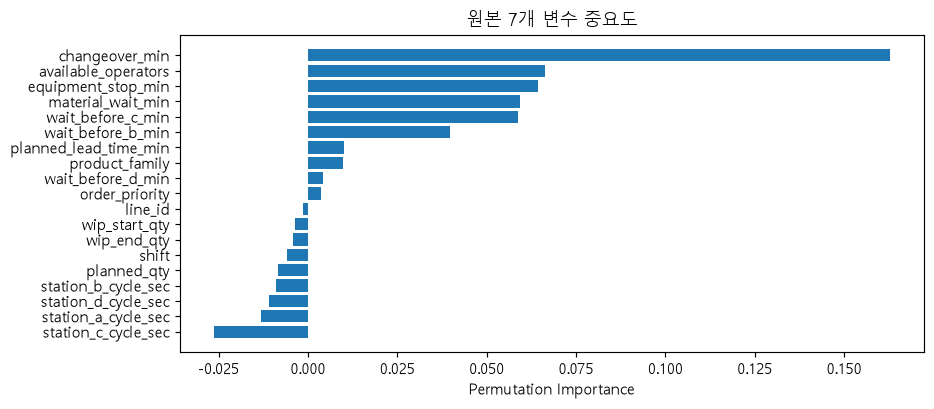

In [22]:
# ============================================================
# 그래프 05. 원본 7개 Feature Importance
# ============================================================

plt.figure(figsize=(9, 4))

plt.barh(
    imp.variable[::-1],
    imp.importance[::-1]
)

plt.title(
    "원본 7개 변수 중요도"
)

plt.xlabel(
    "Permutation Importance"
)

show_fig("05_importance_original")

,variable,mean_abs_shap_failure
7,changeover_min,0.10287
17,equipment_stop_min,0.06309
18,material_wait_min,0.04221
5,available_operators,0.03279
12,wait_before_b_min,0.02724
10,station_c_cycle_sec,0.01985
13,wait_before_c_min,0.01979
2,product_family,0.01362
14,wait_before_d_min,0.01332
16,wip_end_qty,0.01202


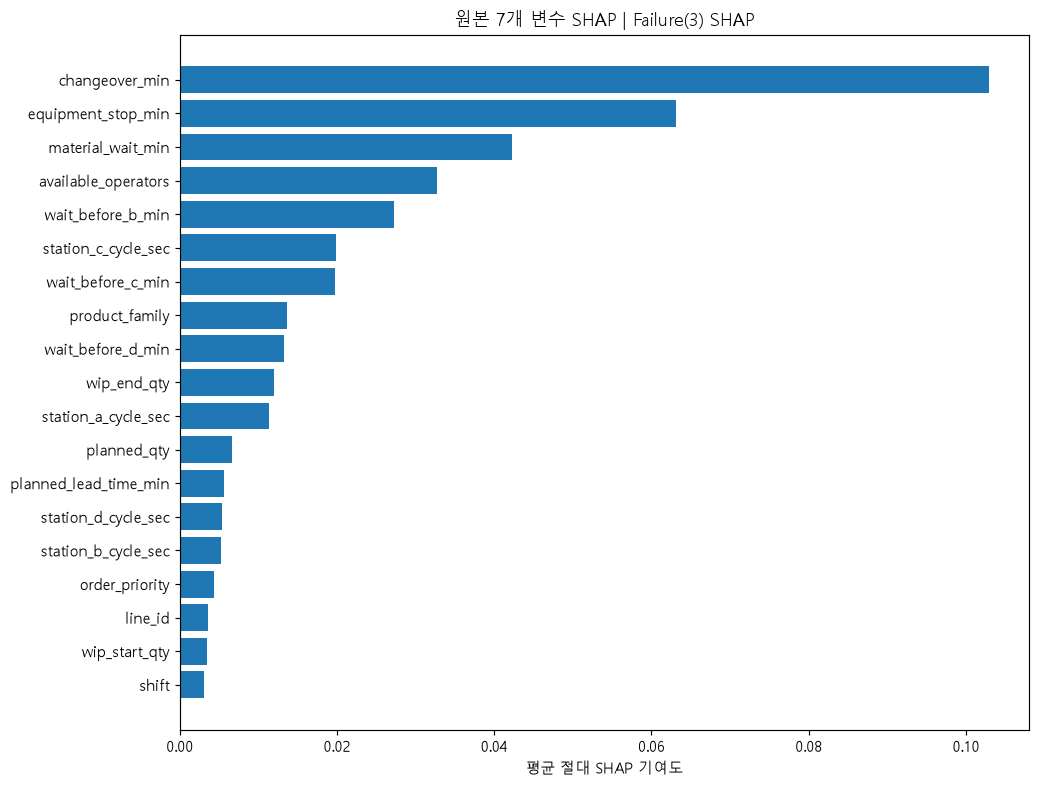

In [23]:
# ============================================================
# 그래프 19. 원본 7개 SHAP 분석
# ============================================================

shap_original = plot_shap_rf(
    BASE,
    "19_shap_original7",
    "원본 7개 변수 SHAP"
)

In [24]:
# ============================================================
# STEP 2-4. 원본 중요 변수 Top 5 / Top 7
# ============================================================

TOP5 = imp.variable.tolist()[:5]
TOP7 = imp.variable.tolist()[:7]

for k, cols in [
    (5, TOP5),
    (7, TOP7)
]:

    fit_eval(
        f"2단계_Top{k}",
        cols,
        best_alg
    )

In [25]:
# ============================================================
# STEP 3. 파생변수 및 PCA
# ============================================================

print(
    "\n========== STEP 3. 파생변수 / PCA =========="
)


========== STEP 3. 파생변수 / PCA ==========


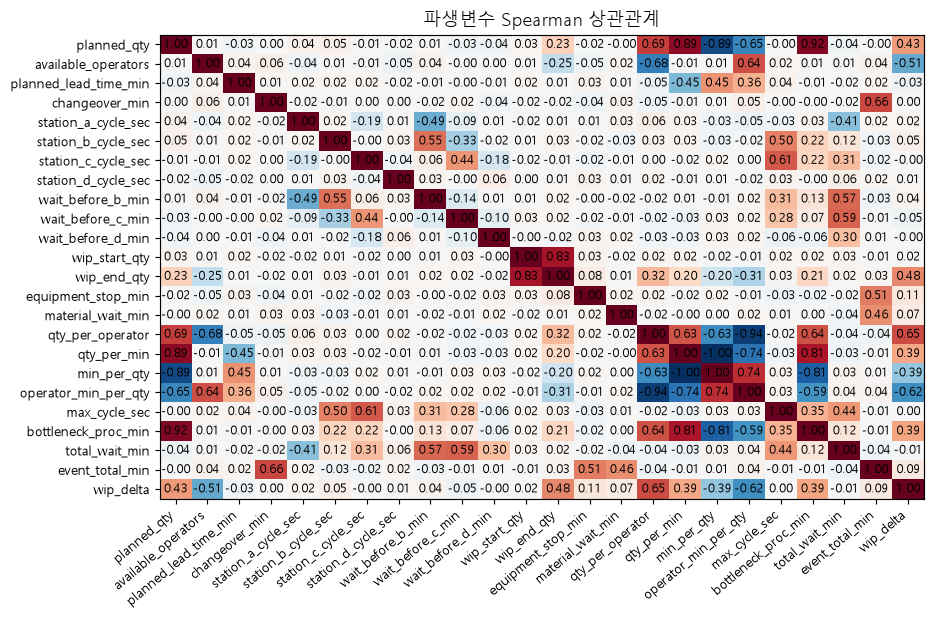

In [26]:
# ============================================================
# 히트맵 06. 파생변수 상관관계
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

heatmap(
    ax,
    train_ex[
        NUM + DERIVED
    ].corr(method="spearman"),
    "파생변수 Spearman 상관관계",
    "RdBu_r",
    ".2f",
    -1,
    1
)

show_fig("06_derived_corr")

In [27]:
# ============================================================
# STEP 3-1. 확장 변수 중요도
# ============================================================

imp_ex = rank_features(EXT)

display(
    imp_ex.round(4)
)

imp_ex.to_csv(
    OUT / "03_importance_extended.csv",
    index=False,
    encoding="utf-8-sig"
)

,variable,importance
26,event_total_min,0.1941
25,total_wait_min,0.0814
7,changeover_min,0.0479
5,available_operators,0.0353
19,qty_per_operator,0.0289
4,planned_qty,0.0236
12,wait_before_b_min,0.0201
8,station_a_cycle_sec,0.0146
21,min_per_qty,0.0140
9,station_b_cycle_sec,0.0111


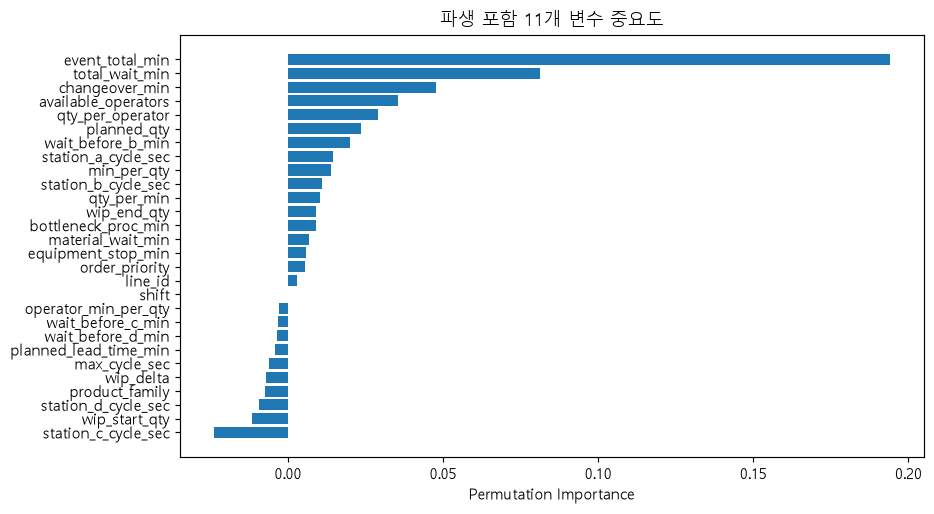

In [28]:
# ============================================================
# 그래프 07. 확장 11개 Feature Importance
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.barh(
    imp_ex.variable[::-1],
    imp_ex.importance[::-1]
)

plt.title(
    "파생 포함 11개 변수 중요도"
)

plt.xlabel(
    "Permutation Importance"
)

show_fig("07_importance_extended")

,variable,mean_abs_shap_failure
26,event_total_min,0.11373
7,changeover_min,0.05913
25,total_wait_min,0.03687
17,equipment_stop_min,0.02907
5,available_operators,0.02299
18,material_wait_min,0.02052
12,wait_before_b_min,0.01406
10,station_c_cycle_sec,0.01343
13,wait_before_c_min,0.00917
23,max_cycle_sec,0.00851


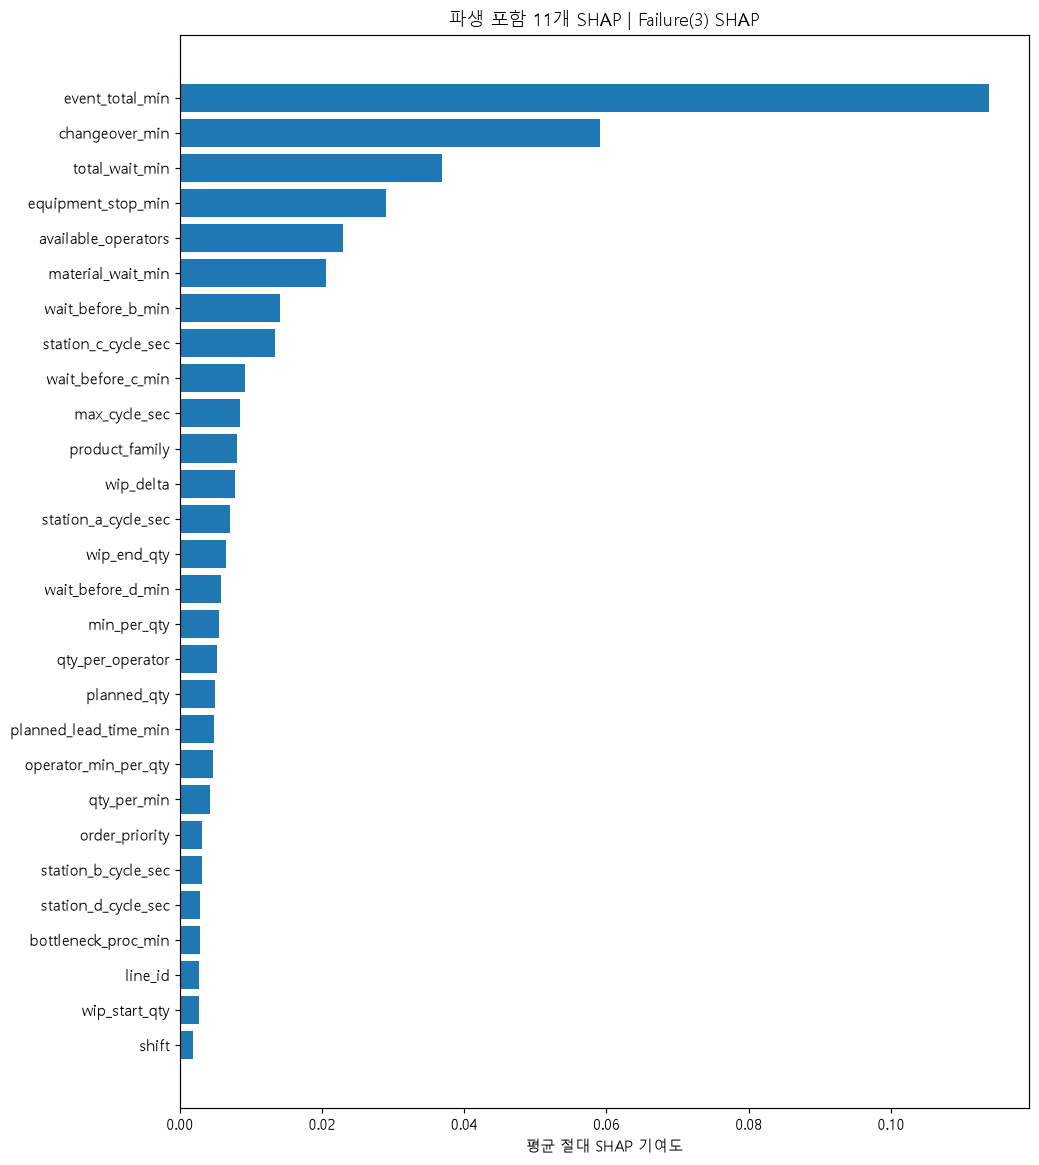

In [29]:
# ============================================================
# 그래프 20. 확장 11개 SHAP 분석
# ============================================================

shap_extended = plot_shap_rf(
    EXT,
    "20_shap_extended11",
    "파생 포함 11개 SHAP"
)

In [30]:
# ============================================================
# STEP 3-2. 확장 Top 5 / 7 / 10 비교
# ============================================================

EX_TOP7 = imp_ex.variable.tolist()[:7]

for k in [5, 7, 10]:

    selected = (
        imp_ex.variable.tolist()[:k]
    )

    fit_eval(
        f"3단계_확장Top{k}",
        selected,
        best_alg
    )

# 파생변수 전체 11개
fit_eval(
    "3단계_파생11개",
    EXT,
    best_alg
)

# PCA 95% 차원 축소
fit_eval(
    "3단계_PCA95",
    EXT,
    best_alg,
    pca=True
)

Pipeline(steps=[('pre',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('cat',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['shift', 'line_id',
                                                   'product_family',
                                                   'order_priority']),
                                                 ('num',
                                                  Pipeline(steps=[('fill',
                                                

In [31]:
# ============================================================
# STEP 4. 단계별 모델 성능 비교
# ============================================================

print(
    "\n========== STEP 4. 성능 비교 =========="
)

# 모든 모델을 학습한 뒤 비교표 생성
# LightGBM 포함 / CatBoost 제외

core_algs = [
    "LogisticRegression",
    "RandomForest",
    "HistGradientBoosting",
    "LightGBM"
]

stage_keys = {}

for alg in core_algs:

    k1 = "기본_" + alg

    if alg == best_alg:
        k2 = "2단계_Top7"
        k3 = "3단계_확장Top7"

    else:
        k2 = f"2단계_{alg}"
        k3 = f"3단계_{alg}"

    fit_eval(
        k2,
        TOP7,
        alg
    )

    fit_eval(
        k3,
        EX_TOP7,
        alg
    )

    stage_keys[alg] = (
        k1,
        k2,
        k3
    )


========== STEP 4. 성능 비교 ==========


In [32]:
# ============================================================
# STEP 4-1. 최종 성능표 생성
# ============================================================

comparison = pd.DataFrame(
    records
).sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

display(
    comparison.round(4)
)

comparison.to_csv(
    OUT / "04_validation_scores.csv",
    index=False,
    encoding="utf-8-sig"
)

best_key = (
    comparison.iloc[0]["구성"]
)

print(
    "내부 검증 최종 선택:",
    best_key
)

,구성,모델,변수수,accuracy,macro_f1,failure_recall,failure_precision,failure_ap,qwk
0,3단계_확장Top10,LogisticRegression,10,0.6484,0.6542,0.7536,0.7222,0.8245,0.7877
1,3단계_확장Top7,LogisticRegression,7,0.6409,0.6476,0.7246,0.7042,0.8284,0.7904
2,3단계_확장Top5,LogisticRegression,5,0.6359,0.6420,0.7101,0.7000,0.8213,0.7880
3,3단계_파생11개,LogisticRegression,28,0.6284,0.6332,0.7246,0.7353,0.8210,0.7786
4,기본_LogisticRegression,LogisticRegression,19,0.6209,0.6232,0.7246,0.7246,0.8238,0.7771
5,3단계_HistGradientBoosting,HistGradientBoosting,7,0.6234,0.6197,0.6087,0.7241,0.7594,0.7512
6,3단계_PCA95,LogisticRegression,28,0.6135,0.6159,0.6812,0.6812,0.8203,0.7670
7,3단계_LightGBM,LightGBM,7,0.6160,0.6142,0.5797,0.7692,0.7719,0.7452
8,2단계_RandomForest,RandomForest,7,0.5985,0.6046,0.6522,0.6618,0.7131,0.7385
9,2단계_LightGBM,LightGBM,7,0.6035,0.6043,0.5942,0.7593,0.7205,0.7319


내부 검증 최종 선택: 3단계_확장Top10


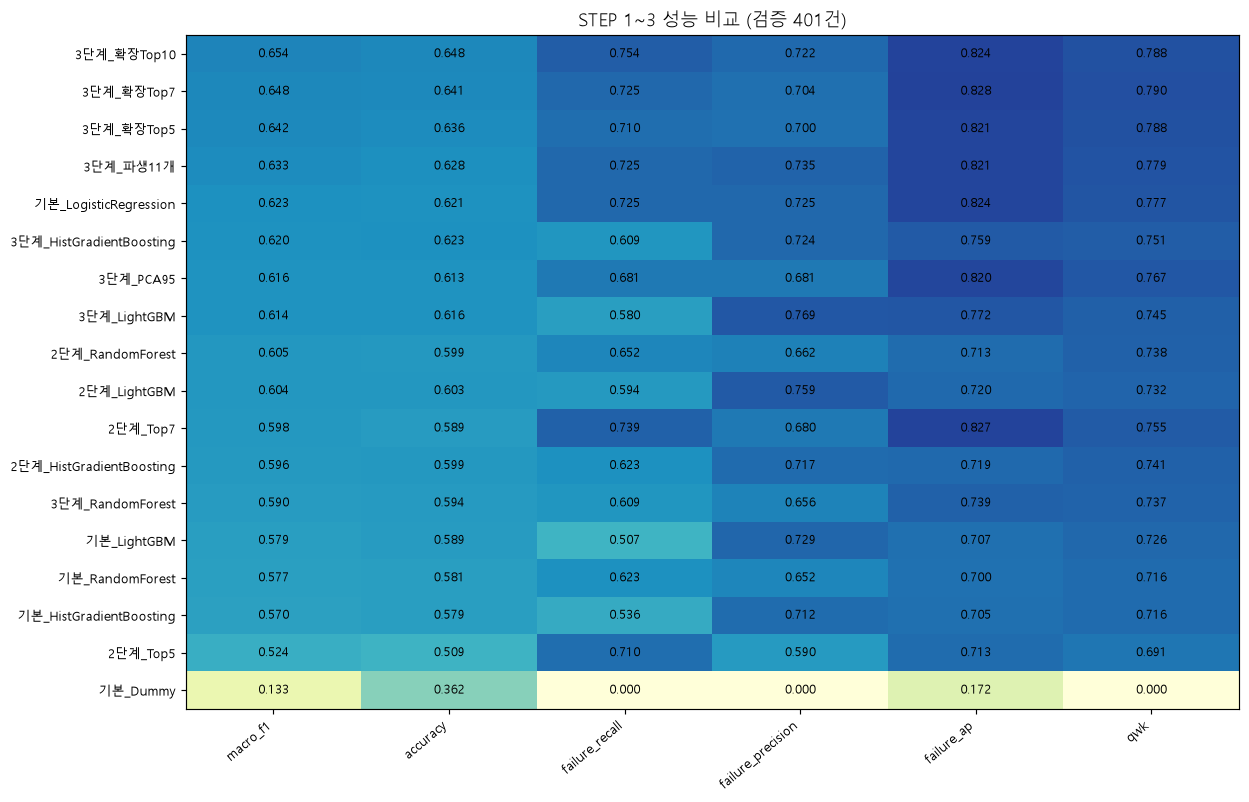

In [33]:
# ============================================================
# 히트맵 08. 단계별 성능 비교
# ============================================================

metrics = [
    "macro_f1",
    "accuracy",
    "failure_recall",
    "failure_precision",
    "failure_ap",
    "qwk"
]

fig, ax = plt.subplots(
    figsize=(
        12,
        max(5, 0.43 * len(comparison))
    )
)

heatmap(
    ax,
    comparison.set_index(
        "구성"
    )[metrics],
    f"STEP 1~3 성능 비교 (검증 {len(valid)}건)",
    "YlGnBu",
    ".3f",
    0,
    1
)

show_fig(
    "08_validation_score_heatmap"
)

In [34]:
# ============================================================
# STEP 4-2. 혼동행렬과 PR 곡선 공통 함수
# ============================================================

def confusion_pr(
    truth, pred, prob,
    title, filename
):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5)
    )

    cm = confusion_matrix(
        truth,
        pred,
        labels=range(4)
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=NAMES
    ).plot(
        ax=axes[0],
        cmap="Blues",
        colorbar=False
    )

    axes[0].set_title(
        title + " 혼동행렬"
    )

    precision, recall, _ = (
        precision_recall_curve(
            truth == 3,
            prob
        )
    )

    ap = average_precision_score(
        truth == 3,
        prob
    )

    axes[1].plot(
        recall,
        precision,
        label=f"Failure AP={ap:.3f}"
    )

    axes[1].axhline(
        (truth == 3).mean(),
        ls="--",
        color="gray",
        label="Failure 실제 비율"
    )

    axes[1].set(
        xlabel="Recall",
        ylabel="Precision",
        title=title + " Failure PR 곡선"
    )

    axes[1].legend()

    show_fig(filename)


def class3_probability(model, x):

    return model.predict_proba(x)[
        :,
        list(
            model.classes_
        ).index(3)
    ]

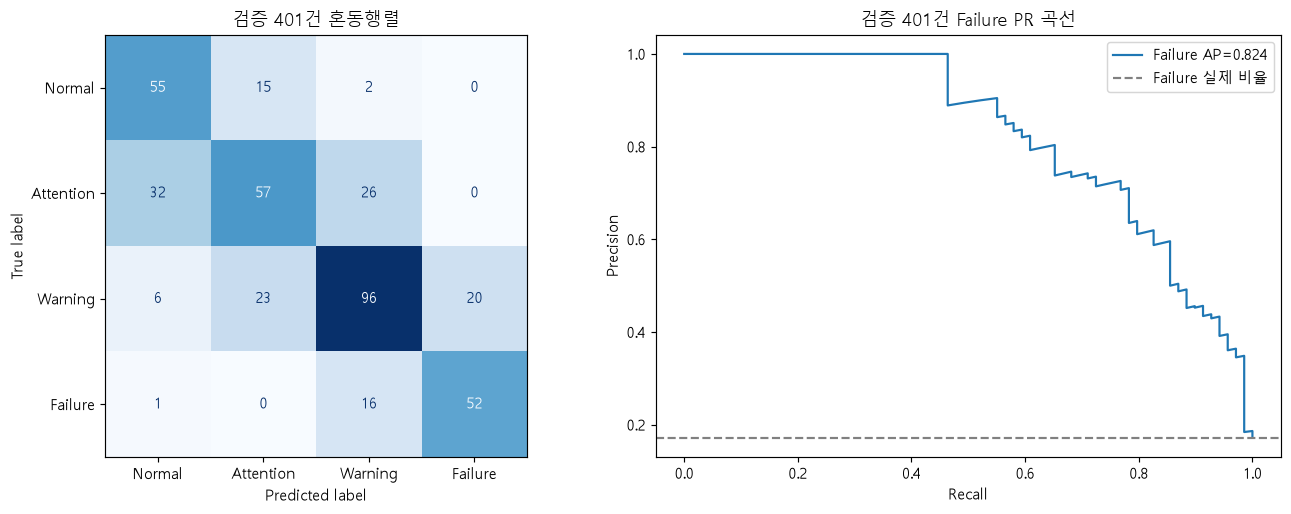

In [35]:
# ============================================================
# 그래프 09. 내부 검증 혼동행렬 + PR 곡선
# ============================================================

bm = models[best_key]

best_cols = (
    configurations[best_key][0]
)

confusion_pr(
    y_valid,
    bm.predict(
        valid_ex[best_cols]
    ),
    class3_probability(
        bm,
        valid_ex[best_cols]
    ),
    f"검증 {len(valid)}건",
    "09_validation_cm_pr"
)

In [36]:
# ============================================================
# STEP 4-3. ROC/AUC 시각화 공통 함수
# ============================================================

def plot_roc(
    keys,
    title,
    filename,
    aliases=None
):

    plt.figure(
        figsize=(11, 7)
    )

    results = {}

    for key in keys:

        if (
            key not in models
            or "Dummy" in key
        ):
            continue

        m = models[key]

        cols = (
            configurations[key][0]
        )

        p = class3_probability(
            m,
            valid_ex[cols]
        )

        fpr, tpr, _ = roc_curve(
            y_valid == 3,
            p
        )

        area = auc(
            fpr,
            tpr
        )

        label = (
            aliases.get(key, key)
            if aliases
            else key
        )

        plt.plot(
            fpr,
            tpr,
            lw=1.7,
            label=(
                f"{label} "
                f"(AUC={area:.3f})"
            )
        )

        results[label] = area

    plt.plot(
        [0, 1],
        [0, 1],
        "--",
        color="gray"
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1.05)

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(title)
    plt.grid(alpha=0.25)

    plt.legend(
        loc="lower right",
        fontsize=8
    )

    show_fig(filename)

    return results

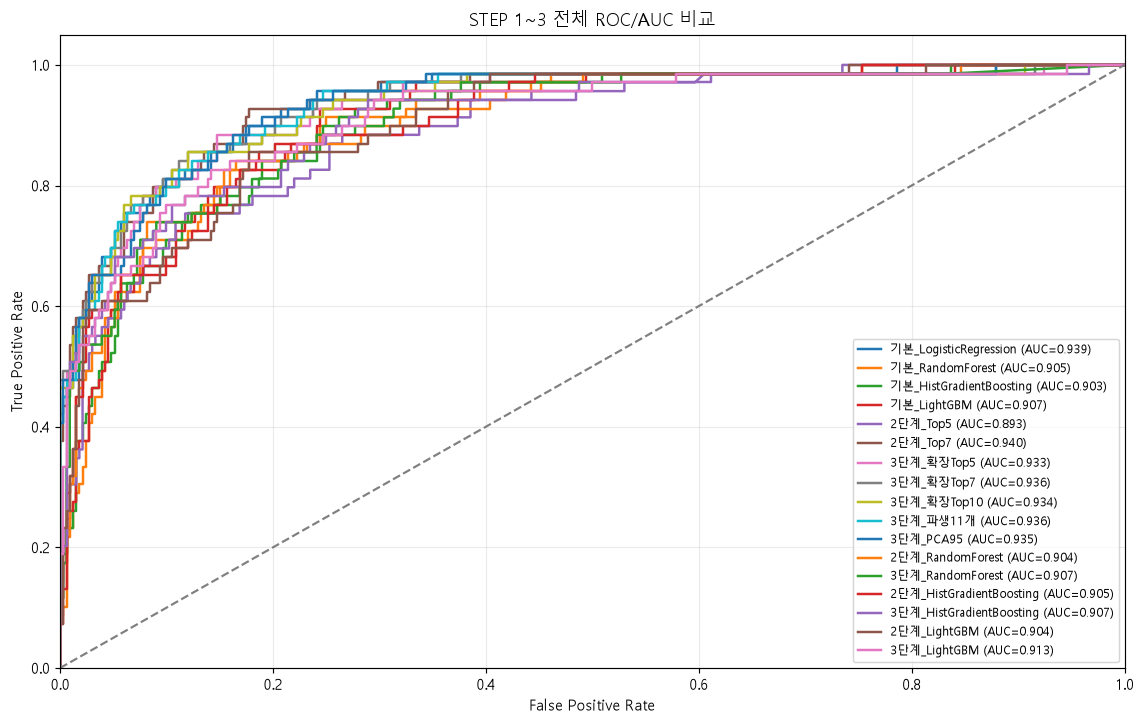

{'기본_LogisticRegression': 0.9388859786973983,
 '기본_RandomForest': 0.9045748210232233,
 '기본_HistGradientBoosting': 0.9030033176182992,
 '기본_LightGBM': 0.9068884232582504,
 '2단계_Top5': 0.8934215121354985,
 '2단계_Top7': 0.9395844246551422,
 '3단계_확장Top5': 0.9325563122053432,
 '3단계_확장Top7': 0.9358739305046272,
 '3단계_확장Top10': 0.9337349397590362,
 '3단계_파생11개': 0.9360921948664223,
 '3단계_PCA95': 0.9353937489086783,
 '2단계_RandomForest': 0.9042692509167102,
 '3단계_RandomForest': 0.9067356382049938,
 '2단계_HistGradientBoosting': 0.9054042255980443,
 '3단계_HistGradientBoosting': 0.9071503404924044,
 '2단계_LightGBM': 0.9036144578313253,
 '3단계_LightGBM': 0.9128688667714335}

In [37]:
# ============================================================
# 그래프 14. 전체 모델 ROC/AUC 비교
# ============================================================

ordered_keys = [
    k for k in models
    if "Dummy" not in k
]

plot_roc(
    ordered_keys,
    "STEP 1~3 전체 ROC/AUC 비교",
    "14_all_models_roc"
)

In [38]:
# ============================================================
# STEP 4-4. 실제 점수를 이용한 성능 변화
# ============================================================

all_scores = pd.DataFrame(
    records
).set_index("구성")

stage_f1 = pd.DataFrame(

    {
        alg: [
            all_scores.loc[
                k, "macro_f1"
            ]
            for k in keys
        ]

        for alg, keys
        in stage_keys.items()
    },

    index=[
        "1단계 기본",
        "2단계 Top7",
        "3단계 확장 Top7"
    ]
)

print(
    "\n모델별 STEP별 실제 Macro F1"
)

display(
    stage_f1.round(4)
)

stage_f1.to_csv(
    OUT / "05_stage_f1.csv",
    encoding="utf-8-sig"
)


모델별 STEP별 실제 Macro F1


,LogisticRegression,RandomForest,HistGradientBoosting,LightGBM
1단계 기본,0.6232,0.5774,0.5704,0.5786
2단계 Top7,0.5977,0.6046,0.5964,0.6043
3단계 확장 Top7,0.6476,0.5898,0.6197,0.6142


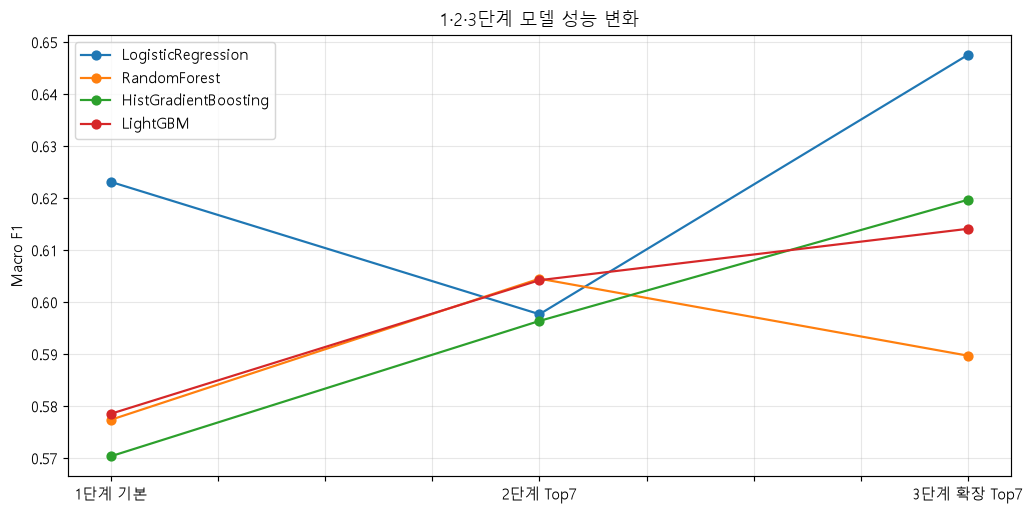

In [39]:
# ============================================================
# 그래프 15. 단계별 Macro F1 변화
# ============================================================

stage_f1.plot(
    marker="o",
    figsize=(10, 5)
)

plt.title(
    "1·2·3단계 모델 성능 변화"
)

plt.ylabel("Macro F1")
plt.grid(alpha=0.3)

show_fig("15_real_stage_trend")

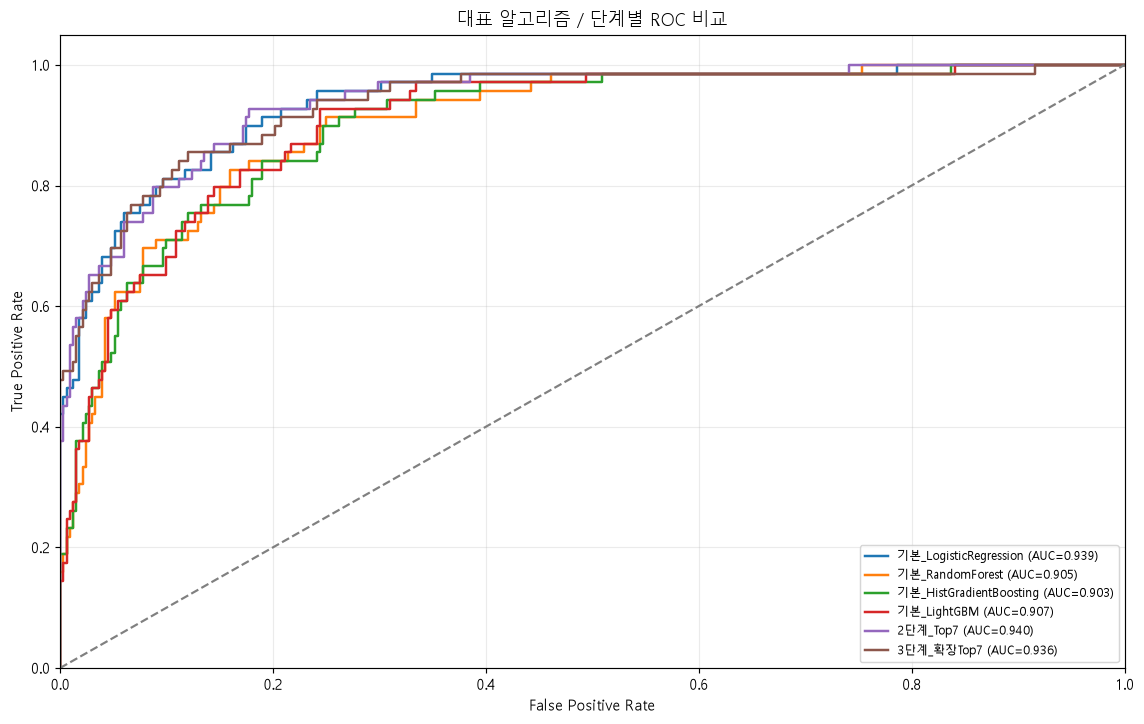

{'기본_LogisticRegression': 0.9388859786973983,
 '기본_RandomForest': 0.9045748210232233,
 '기본_HistGradientBoosting': 0.9030033176182992,
 '기본_LightGBM': 0.9068884232582504,
 '2단계_Top7': 0.9395844246551422,
 '3단계_확장Top7': 0.9358739305046272}

In [40]:
# ============================================================
# 그래프 16. 대표 모델 ROC 비교
# ============================================================

core_keys = [
    "기본_LogisticRegression",
    "기본_RandomForest",
    "기본_HistGradientBoosting",
    "기본_LightGBM",
    "2단계_Top7",
    "3단계_확장Top7"
]

plot_roc(
    core_keys,
    "대표 알고리즘 / 단계별 ROC 비교",
    "16_core_models_roc"
)

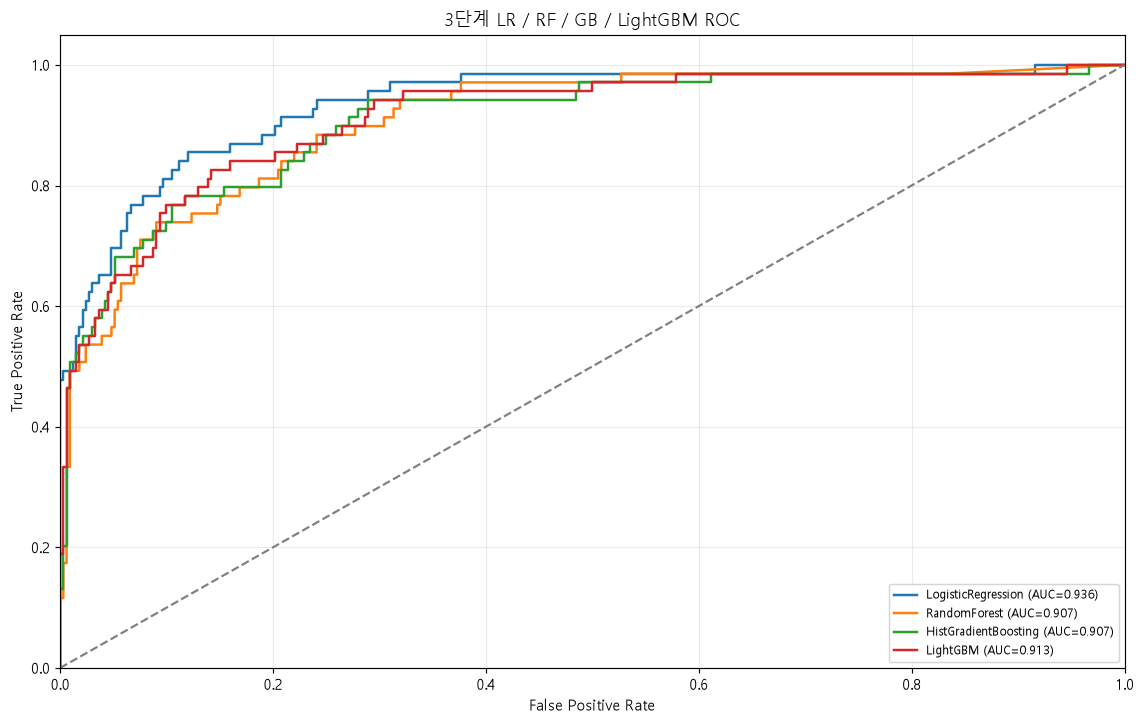

In [41]:
# ============================================================
# 그래프 17. STEP 3 최종 ROC
# ============================================================

final3 = [
    stage_keys[a][2]
    for a in core_algs
]

aliases = {
    stage_keys[a][2]: a
    for a in core_algs
}

aucs = plot_roc(
    final3,
    "3단계 LR / RF / GB / LightGBM ROC",
    "17_stage3_roc",
    aliases
)

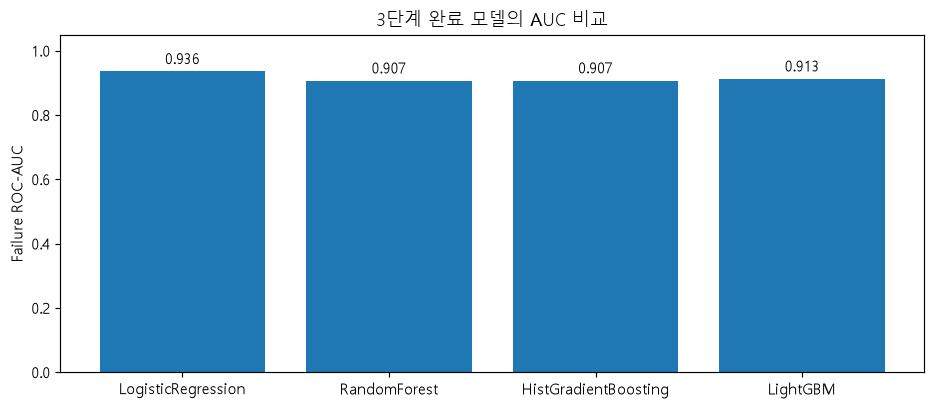

In [42]:
# ============================================================
# 그래프 18. STEP 3 모델 AUC 비교
# ============================================================

plt.figure(figsize=(9, 4))

bars = plt.bar(
    list(aucs),
    list(aucs.values())
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

plt.ylim(0, 1.05)

plt.ylabel(
    "Failure ROC-AUC"
)

plt.title(
    "3단계 완료 모델의 AUC 비교"
)

show_fig("18_stage3_auc")

In [43]:
# ============================================================
# STEP 4-5. 3구간 Expanding 검증
# ============================================================

print(
    "\n[STEP 4 보조] 3구간 Expanding 검증"
)

# 주의:
# 마지막 75:25 검증 구간은 그대로 유지
# 학습 구간 안에서만 3구간 검증 수행

rolling_rows = []

ordered_train = train.sort_values(
    [
        "lot_start_time",
        "record_id"
    ]
).reset_index(drop=True)

nroll = len(ordered_train)

for fold in range(3):

    sidx = int(
        nroll * (fold + 1) / 4
    )

    if fold < 2:

        eidx = int(
            nroll * (fold + 2) / 4
        )

    else:

        eidx = nroll

    begin_t = ordered_train.iloc[
        sidx
    ].lot_start_time

    if fold < 2:

        end_t = ordered_train.iloc[
            eidx
        ].lot_start_time

    else:

        end_t = None

    pool = ordered_train[
        ordered_train.lot_start_time < begin_t
    ].copy()

    complete_at = (
        pool.lot_start_time
        + pd.to_timedelta(
            pool.actual_lead_time_min,
            unit="m"
        )
    )

    fitting = pool[
        complete_at <= begin_t
    ].copy()

    testing = ordered_train[
        ordered_train.lot_start_time >= begin_t
    ].copy()

    if end_t is not None:

        testing = testing[
            testing.lot_start_time < end_t
        ].copy()

    for alg_fold in core_algs:

        m = pipeline(
            BASE,
            alg_fold
        )

        m.fit(
            fitting[BASE],
            fitting.y
        )

        result = score(
            m,
            testing[BASE],
            testing.y
        )

        rolling_rows.append({

            "구간": f"{fold+1}회",
            "알고리즘": alg_fold,
            "학습수": len(fitting),
            "검증수": len(testing),

            **result
        })


rolling = pd.DataFrame(
    rolling_rows
)

display(
    rolling.round(4)
)

rolling.to_csv(
    OUT / "06_rolling_3fold.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "\n3구간 평균 Macro F1 / 표준편차"
)

display(
    rolling.groupby(
        "알고리즘"
    ).macro_f1.agg(
        ["mean", "std"]
    ).round(4)
)


[STEP 4 보조] 3구간 Expanding 검증


,구간,알고리즘,학습수,검증수,accuracy,macro_f1,failure_recall,failure_precision,failure_ap,qwk
0,1회,LogisticRegression,298,299,0.5953,0.6031,0.7800,0.6724,0.7948,0.7454
1,1회,RandomForest,298,299,0.4716,0.4403,0.4200,0.5833,0.6194,0.5649
2,1회,HistGradientBoosting,298,299,0.5351,0.5120,0.3600,0.6207,0.6256,0.5665
3,1회,LightGBM,298,299,0.5184,0.4987,0.4000,0.6897,0.6793,0.5708
4,2회,LogisticRegression,596,299,0.6689,0.6748,0.9362,0.7586,0.9140,0.8143
5,2회,RandomForest,596,299,0.5786,0.5709,0.7021,0.7333,0.8356,0.7054
6,2회,HistGradientBoosting,596,299,0.5619,0.5529,0.5532,0.7429,0.7920,0.6662
7,2회,LightGBM,596,299,0.5552,0.5534,0.5319,0.6944,0.7815,0.6844
8,3회,LogisticRegression,893,300,0.6067,0.6235,0.7447,0.7000,0.8766,0.7880
9,3회,RandomForest,893,300,0.5833,0.5837,0.5319,0.7576,0.7617,0.7133



3구간 평균 Macro F1 / 표준편차


,mean,std
알고리즘,,
HistGradientBoosting,0.5426,0.0269
LightGBM,0.5316,0.0290
LogisticRegression,0.6338,0.0369
RandomForest,0.5316,0.0794


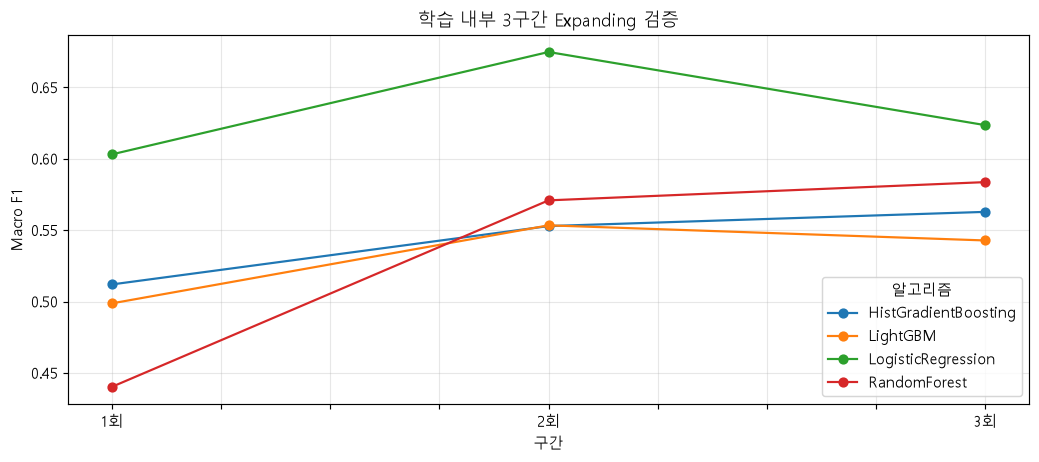

In [44]:
# ============================================================
# 그래프 21. 3구간 검증 성능 추이
# ============================================================

rolling.pivot(
    index="구간",
    columns="알고리즘",
    values="macro_f1"
).plot(
    marker="o",
    figsize=(10, 4.5),
    title="학습 내부 3구간 Expanding 검증"
)

plt.ylabel("Macro F1")
plt.grid(alpha=0.3)

show_fig("21_rolling_3fold")

In [45]:
# ============================================================
# STEP 5. Blind Test 최종 평가
# ============================================================

print(
    "\n========== STEP 5. Blind 평가 =========="
)

cols, alg, pca = (
    configurations[best_key]
)

# 최종 모델만 원본 전체 1600건 재학습
full_ex = enrich(original)
blind_ex = enrich(blind)

final = pipeline(
    cols,
    alg,
    pca
)

final.fit(
    full_ex[cols],
    original.y
)

# Blind 1600건 예측
y_pred = final.predict(
    blind_ex[cols]
)

p_failure = class3_probability(
    final,
    blind_ex[cols]
)

final_result = score(
    final,
    blind_ex[cols],
    y_blind
)

print(
    "최종 선택된 모델:",
    best_key
)

display(
    pd.DataFrame(
        [final_result]
    ).round(4)
)

print(
    classification_report(
        y_blind,
        y_pred,
        labels=range(4),
        target_names=NAMES,
        zero_division=0
    )
)


========== STEP 5. Blind 평가 ==========
최종 선택된 모델: 3단계_확장Top10


,accuracy,macro_f1,failure_recall,failure_precision,failure_ap,qwk
0,0.4312,0.4408,0.9885,0.3373,0.8307,0.636


              precision    recall  f1-score   support

      Normal       0.81      0.53      0.64       459
   Attention       0.53      0.28      0.36       615
     Warning       0.22      0.30      0.26       352
     Failure       0.34      0.99      0.50       174

    accuracy                           0.43      1600
   macro avg       0.48      0.52      0.44      1600
weighted avg       0.52      0.43      0.43      1600



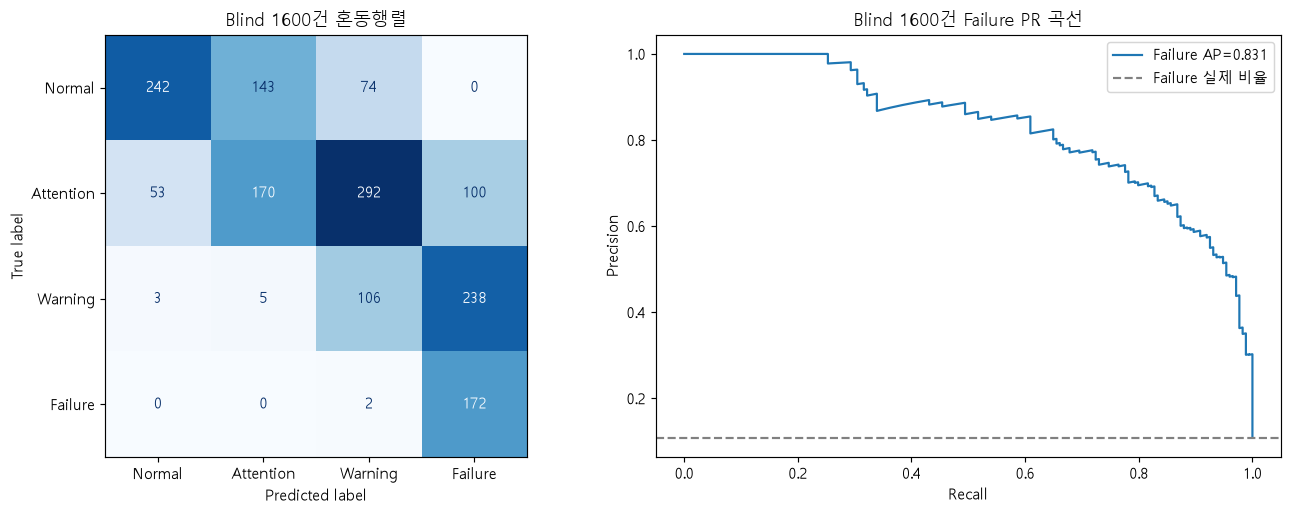

In [46]:
# ============================================================
# 그래프 10. Blind 혼동행렬 + PR 곡선
# ============================================================

confusion_pr(
    y_blind,
    y_pred,
    p_failure,
    "Blind 1600건",
    "10_blind_cm_pr"
)

In [47]:
# ============================================================
# STEP 5-2. Blind 오예측 분석
# ============================================================

post = blind[
    [
        "record_id",
        "product_family",
        "actual_bottleneck_station",
        "scenario_code"
    ]
].copy()

post["actual"] = y_blind
post["predicted"] = y_pred
post["p_failure"] = p_failure

post["failure_missed"] = (
    (y_blind == 3)
    & (y_pred != 3)
)

post["severe_missed"] = (
    (y_blind == 3)
    & (y_pred <= 1)
)

post.to_csv(
    OUT / "05_blind_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Failure 실제:",
    (y_blind == 3).sum()
)

print(
    "Failure 미탐:",
    post.failure_missed.sum()
)

print(
    "심각한 과소예측:",
    post.severe_missed.sum()
)

Failure 실제: 174
Failure 미탐: 2
심각한 과소예측: 0


In [48]:
# ============================================================
# STEP 5-3. 이상 시나리오와 병목 위치 분석
# ============================================================

# 사후 정답 분석 전용
# 실제 병목 위치 / 시나리오 코드는
# 사전 예측 모델의 입력 X로 사용하지 않음

scenario = post.groupby(
    "scenario_code"
).agg(

    total=(
        "record_id",
        "size"
    ),

    failures=(
        "actual",
        lambda s: int(
            (s == 3).sum()
        )
    )

)

scenario["failure_rate"] = (
    100
    * scenario.failures
    / scenario.total
)

display(
    scenario.round(2)
)

bottleneck = pd.crosstab(
    post.actual_bottleneck_station,
    post.actual
).reindex(
    columns=range(4),
    fill_value=0
)

,total,failures,failure_rate
scenario_code,,,
B_QUEUE,86,21,24.42
C_MATERIAL,86,85,98.84
D_STOP,71,42,59.15
HIGH_MIX,66,3,4.55
NORMAL,1291,23,1.78


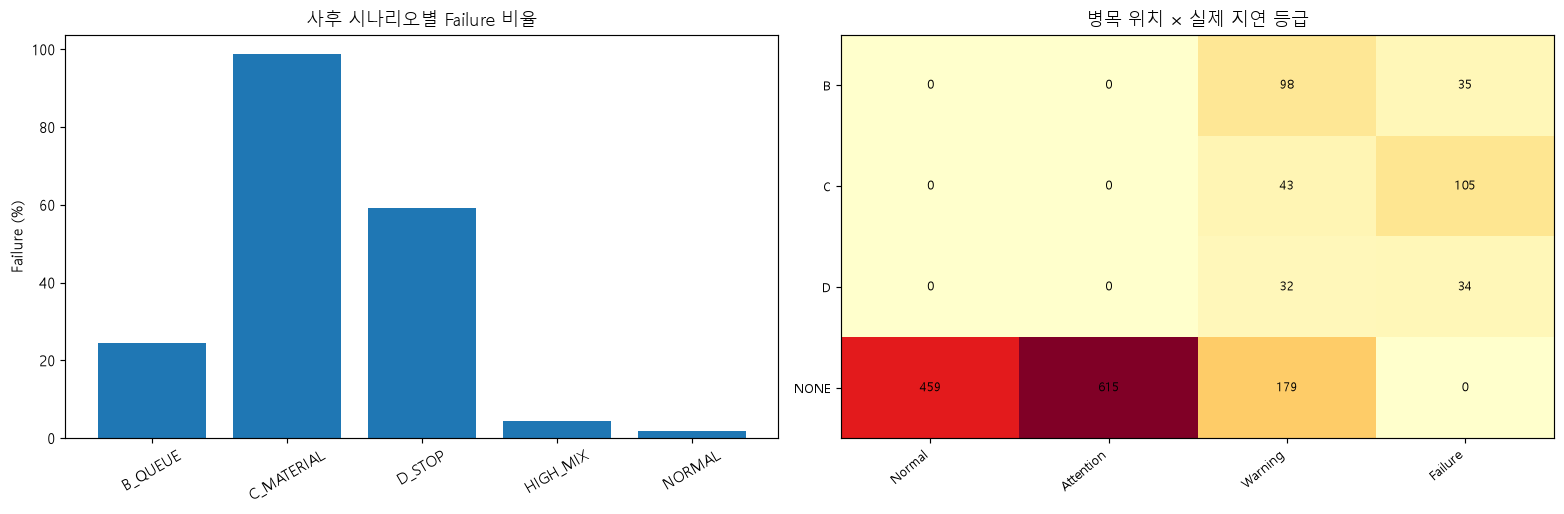

In [49]:
# ============================================================
# 그래프 11. 이상 시나리오 + 병목 히트맵
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

axes[0].bar(
    scenario.index,
    scenario.failure_rate
)

axes[0].tick_params(
    axis="x",
    rotation=30
)

axes[0].set(
    title="사후 시나리오별 Failure 비율",
    ylabel="Failure (%)"
)

heatmap(
    axes[1],
    bottleneck.rename(
        columns=dict(
            enumerate(NAMES)
        )
    ),
    "병목 위치 × 실제 지연 등급",
    "YlOrRd",
    ".0f"
)

show_fig("11_posthoc_scenarios")

In [50]:
# ============================================================
# STEP 5-4. 제품군별 Failure 미탐
# ============================================================

miss = post.groupby(
    "product_family"
).agg(

    actual_failure=(
        "actual",
        lambda s: int(
            (s == 3).sum()
        )
    ),

    missed=(
        "failure_missed",
        "sum"
    )

)

display(miss)

,actual_failure,missed
product_family,,
PF1,46,1
PF2,61,1
PF3,67,0


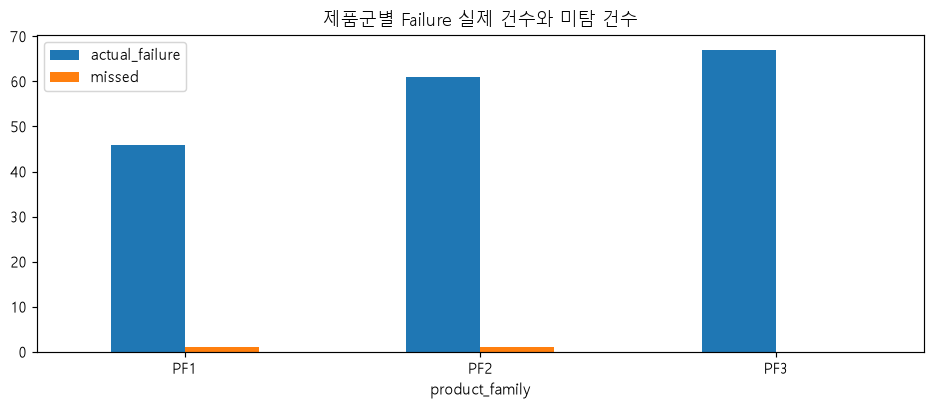

In [51]:
# ============================================================
# 그래프 12. 제품군별 Failure 미탐
# ============================================================

miss.plot(
    kind="bar",
    figsize=(9, 4),
    rot=0,
    title="제품군별 Failure 실제 건수와 미탐 건수"
)

show_fig(
    "12_failure_misses_by_product"
)

In [52]:
# ============================================================
# STEP 5-5. 동일한 입력조건의 정답 변화 분석
# ============================================================

shared = blind[
    BASE + ["y"]
].merge(

    original[
        BASE + ["y"]
    ].rename(
        columns={
            "y": "old_y"
        }
    ),

    on=BASE,
    how="left",
    validate="many_to_one"
)

print(
    "원본에 동일한 입력이 있는 Blind 비율:",
    f"{shared.old_y.notna().mean():.1%}"
)

if shared.old_y.notna().all():

    changed = (
        shared.y != shared.old_y
    ).sum()

    print(
        "동일 입력인데 지연등급 변경:",
        changed,
        "건"
    )

    transitions = pd.crosstab(
        shared.old_y,
        shared.y
    ).reindex(
        index=range(4),
        columns=range(4),
        fill_value=0
    )

    transitions.index = NAMES
    transitions.columns = NAMES


    # ========================================================
    # 히트맵 13. 동일 입력 정답 변화
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )

    heatmap(
        ax,
        transitions,
        "동일 입력의 원본 등급 → Blind 정답 변화",
        "YlOrBr",
        ".0f"
    )

    ax.set(
        xlabel="Blind 실제 등급",
        ylabel="원본 실제 등급"
    )

    show_fig(
        "13_reused_inputs_label_shift"
    )

원본에 동일한 입력이 있는 Blind 비율: 78.4%


In [53]:
# ============================================================
# STEP 5-6. 가상 입력 민감도 분석
# ============================================================

print(
    "\n[STEP 5 보조] 입력 민감도 분석"
)

# 모델에 넣는 계획 입력값만 가상으로 변경
# 실제 공정 개선 효과를 의미하지 않음

scenarios = {

    "기존 입력":
        {},

    "작업자 1명 감소": {
        "available_operators":
            lambda x: np.maximum(
                1,
                x - 1
            )
    },

    "계획량 10% 증가": {
        "planned_qty":
            lambda x: np.ceil(
                x * 1.10
            )
    },

    "계획 리드타임 10% 단축": {
        "planned_lead_time_min":
            lambda x: x * 0.90
    }

}

sensitivity_rows = []

for scenario_name, changes in scenarios.items():

    temp = blind.copy()

    for col, func in changes.items():

        temp[col] = func(
            pd.to_numeric(
                temp[col],
                errors="coerce"
            )
        )

    temp_ex = enrich(temp)

    yp = final.predict(
        temp_ex[cols]
    )

    sensitivity_rows.append({

        "가상 변화":
            scenario_name,

        "등급변경률(%)":
            100 * np.mean(
                yp != y_pred
            ),

        "Failure경보율(%)":
            100 * np.mean(
                yp == 3
            ),

        "Failure경보수":
            int(
                np.sum(yp == 3)
            )

    })

sensitivity = pd.DataFrame(
    sensitivity_rows
).set_index(
    "가상 변화"
)

display(
    sensitivity.round(2)
)

sensitivity.to_csv(
    OUT / "07_input_sensitivity.csv",
    encoding="utf-8-sig"
)


[STEP 5 보조] 입력 민감도 분석


,등급변경률(%),Failure경보율(%),Failure경보수
가상 변화,,,
기존 입력,0.00,31.87,510
작업자 1명 감소,21.94,38.62,618
계획량 10% 증가,0.56,31.37,502
계획 리드타임 10% 단축,1.62,30.75,492


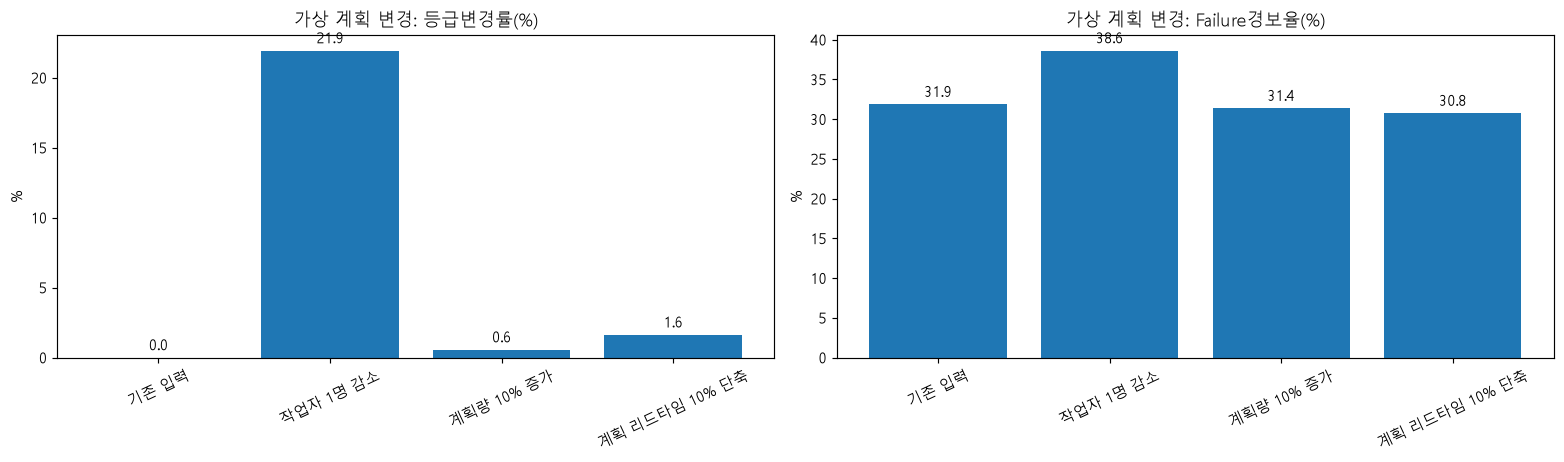

In [54]:
# ============================================================
# 그래프 22. 입력 민감도 비교
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 4.5)
)

for ax, col in zip(

    axes,

    [
        "등급변경률(%)",
        "Failure경보율(%)"
    ]

):

    bars = ax.bar(
        sensitivity.index,
        sensitivity[col]
    )

    ax.set_title(
        f"가상 계획 변경: {col}"
    )

    ax.set_ylabel("%")

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3
    )

    ax.tick_params(
        axis="x",
        rotation=25
    )

show_fig("22_input_sensitivity")

In [55]:
# ============================================================
# STEP 5-7. 오예측 세부 분석
# ============================================================

post["false_failure_alert"] = (
    (post.actual != 3)
    & (post.predicted == 3)
)

error_summary = pd.DataFrame([{

    "실제 Failure":
        int(
            (post.actual == 3).sum()
        ),

    "Failure 경보":
        int(
            (post.predicted == 3).sum()
        ),

    "Failure 적중":
        int(
            (
                (post.actual == 3)
                & (post.predicted == 3)
            ).sum()
        ),

    "Failure 오경보":
        int(
            post.false_failure_alert.sum()
        ),

    "Failure 미탐":
        int(
            post.failure_missed.sum()
        ),

    "심각 과소예측":
        int(
            post.severe_missed.sum()
        )

}])

print(
    "\nFailure 경보 및 오예측 상세"
)

display(
    error_summary
)

error_summary.to_csv(
    OUT / "08_failure_error_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


Failure 경보 및 오예측 상세


,실제 Failure,Failure 경보,Failure 적중,Failure 오경보,Failure 미탐,심각 과소예측
0,174,510,172,338,2,0


In [56]:
# ============================================================
# 히트맵 23. 심각 과소예측 병목 × 제품군
# ============================================================

severe_counts = pd.crosstab(

    post.loc[
        post.severe_missed,
        "actual_bottleneck_station"
    ],

    post.loc[
        post.severe_missed,
        "product_family"
    ]

)

if not severe_counts.empty:

    fig, ax = plt.subplots(
        figsize=(8, 4.5)
    )

    heatmap(
        ax,
        severe_counts,
        "심각 과소예측: 실제 병목 × 제품군",
        "YlOrRd",
        ".0f"
    )

    show_fig(
        "23_severe_misses_bottleneck_family"
    )

    severe_counts.to_csv(
        OUT / "09_severe_misses_cross.csv",
        encoding="utf-8-sig"
    )

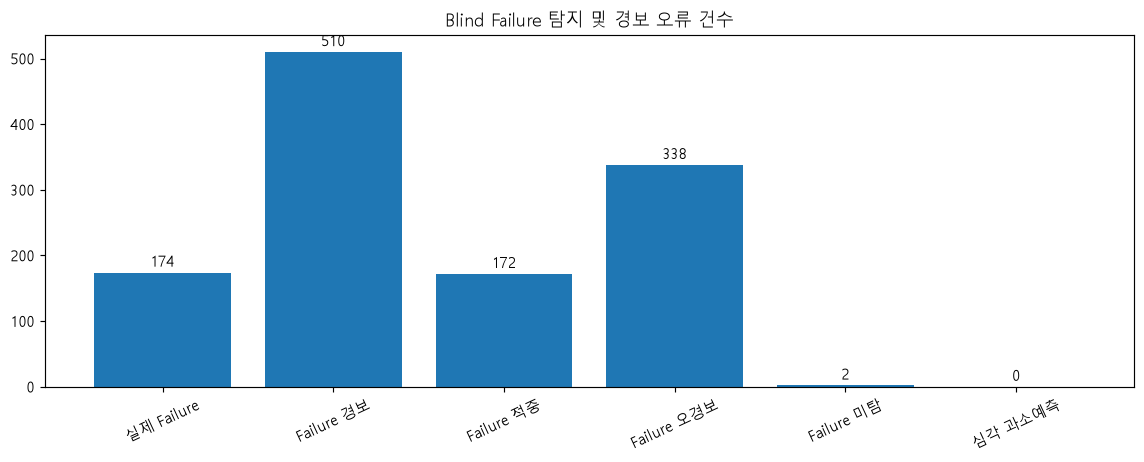

In [57]:
# ============================================================
# 그래프 24. Failure 오예측 건수
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 4.5)
)

summary_vals = (
    error_summary.iloc[0]
)

bars = ax.bar(
    summary_vals.index,
    summary_vals.values
)

ax.bar_label(
    bars,
    padding=2
)

ax.set_title(
    "Blind Failure 탐지 및 경보 오류 건수"
)

ax.tick_params(
    axis="x",
    rotation=25
)

show_fig(
    "24_blind_failure_errors"
)

In [58]:
# ============================================================
# STEP 5-8. PCA 결과 확인
# ============================================================

pca_model = models[
    "3단계_PCA95"
].named_steps["pca"]

print(
    "\nPCA 설명분산:",
    round(
        float(
            sum(
                pca_model.explained_variance_ratio_
            )
        ),
        4
    )
)

print(
    "PCA 주성분 수:",
    pca_model.n_components_
)


# ============================================================
# 최종 분석 결과 출력
# ============================================================

print("\n" + "=" * 55)
print("TEAM 3 캡스톤 분석 완료")
print("=" * 55)

print(
    "학습:",
    len(train),
    "건"
)

print(
    "검증:",
    len(valid),
    "건"
)

print(
    "Blind:",
    len(blind),
    "건"
)

print(
    "\n최종 선택 모델:",
    best_key
)

print(
    "내부 검증 Macro F1:",
    round(
        comparison.iloc[0].macro_f1,
        4
    )
)

print(
    "Blind Macro F1:",
    round(
        final_result["macro_f1"],
        4
    )
)

print(
    "Blind Failure Recall:",
    round(
        final_result["failure_recall"],
        4
    )
)

print(
    "\n그래프 및 CSV 저장 위치:",
    OUT.resolve()
)

print("=" * 55)


PCA 설명분산: 0.9579
PCA 주성분 수: 17

TEAM 3 캡스톤 분석 완료
학습: 1197 건
검증: 401 건
Blind: 1600 건

최종 선택 모델: 3단계_확장Top10
내부 검증 Macro F1: 0.6542
Blind Macro F1: 0.4408
Blind Failure Recall: 0.9885

그래프 및 CSV 저장 위치: C:\Users\user\Desktop\Let-s-Grow\capstone2610\team3_results


## STEP 6. As-Is(계획 7개) vs To-Be(센서 포함) 성능 평가

- **As-Is**: 원본 노트북의 최종 모델과 같은 구성. 계획 변수 Top5(`planned_lead_time_min`, `available_operators`, `line_id`, `product_family`, `shift`) + RandomForest
- **To-Be**: 이 노트북이 내부 검증으로 고른 최종 모델(`best_key`)
- 두 모델 모두 같은 방식으로 평가한다. 내부 검증은 학습 구간으로 학습해 검증 401건으로 평가하고, Blind는 원본 1,600건 전체로 다시 학습해 Blind 1,600건으로 평가한다.
- ⚠️ Blind 정답은 평가에만 쓰고 모델 선택이나 임계값 조정에는 쓰지 않는다.

In [59]:
# ============================================================
# STEP 6-1. As-Is / To-Be 모델 학습·평가
# ============================================================

from sklearn.metrics import confusion_matrix, precision_recall_curve

ASIS_COLS = [
    "planned_lead_time_min",
    "available_operators",
    "line_id",
    "product_family",
    "shift"
]
ASIS_ALG = "RandomForest"

# 원본 노트북 fit_eval과 같은 열 순서(EXT 순서)로 맞춘다
ASIS_COLS = [c for c in EXT if c in ASIS_COLS]

tobe_cols, tobe_alg, tobe_pca = configurations[best_key]


def fit_pair(cols, alg, pca=False):
    """내부 검증용(학습 구간)과 Blind용(원본 전체) 모델을 각각 학습"""
    m_valid = pipeline(cols, alg, pca).fit(train_ex[cols], y_train)
    m_blind = pipeline(cols, alg, pca).fit(full_ex[cols], original.y)
    return m_valid, m_blind


asis_valid, asis_blind = fit_pair(ASIS_COLS, ASIS_ALG)
tobe_valid, tobe_blind = fit_pair(tobe_cols, tobe_alg, tobe_pca)

rows = []
for name, mv, mb, cols in [
    ("As-Is 계획 Top5", asis_valid, asis_blind, ASIS_COLS),
    (f"To-Be {best_key}", tobe_valid, tobe_blind, tobe_cols)
]:
    rows.append({"모델": name, "평가": "내부 검증 401", **score(mv, valid_ex[cols], y_valid)})
    rows.append({"모델": name, "평가": "Blind 1600", **score(mb, blind_ex[cols], y_blind)})

asis_tobe = pd.DataFrame(rows)
display(asis_tobe.round(4))

asis_tobe.to_csv(
    OUT / "10_asis_tobe.csv",
    index=False,
    encoding="utf-8-sig"
)

pred_asis = asis_blind.predict(blind_ex[ASIS_COLS])
pred_tobe = tobe_blind.predict(blind_ex[tobe_cols])
p3_asis = class3_probability(asis_blind, blind_ex[ASIS_COLS])
p3_tobe = class3_probability(tobe_blind, blind_ex[tobe_cols])

for name, pred in [("As-Is", pred_asis), ("To-Be", pred_tobe)]:
    print(
        f"{name}: Failure 경보 {(pred == 3).sum()}건 / "
        f"실제 Failure {(y_blind == 3).sum()}건 / "
        f"놓침 {((y_blind == 3) & (pred != 3)).sum()}건"
    )

,모델,평가,accuracy,macro_f1,failure_recall,failure_precision,failure_ap,qwk
0,As-Is 계획 Top5,내부 검증 401,0.3840,0.3805,0.3913,0.3293,0.2671,0.3009
1,As-Is 계획 Top5,Blind 1600,0.3300,0.3239,0.4080,0.2064,0.1552,0.2870
2,To-Be 3단계_확장Top10,내부 검증 401,0.6484,0.6542,0.7536,0.7222,0.8245,0.7877
3,To-Be 3단계_확장Top10,Blind 1600,0.4312,0.4408,0.9885,0.3373,0.8307,0.6360


As-Is: Failure 경보 344건 / 실제 Failure 174건 / 놓침 103건
To-Be: Failure 경보 510건 / 실제 Failure 174건 / 놓침 2건


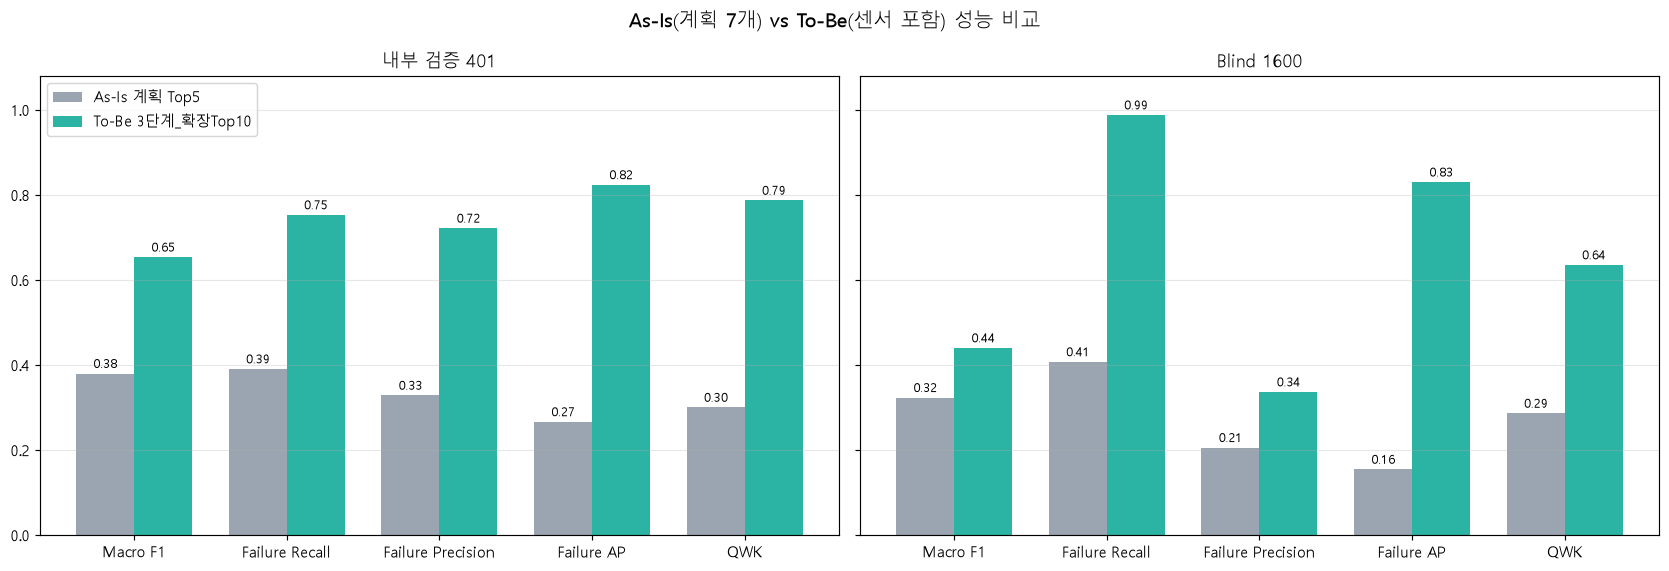

In [60]:
# ============================================================
# 그래프 30. As-Is vs To-Be 지표 비교 (내부 검증 / Blind)
# ============================================================

metric_names = {
    "macro_f1": "Macro F1",
    "failure_recall": "Failure Recall",
    "failure_precision": "Failure Precision",
    "failure_ap": "Failure AP",
    "qwk": "QWK"
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
width = 0.38
x = np.arange(len(metric_names))

for ax, part in zip(axes, ["내부 검증 401", "Blind 1600"]):
    sub_df = asis_tobe[asis_tobe["평가"] == part].set_index("모델")
    for k, (model_name, color) in enumerate(zip(sub_df.index, ["#9aa5b1", "#2bb3a3"])):
        vals = sub_df.loc[model_name, list(metric_names)].astype(float).values
        bars = ax.bar(x + (k - 0.5) * width, vals, width, label=model_name, color=color)
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    ax.set_xticks(x, list(metric_names.values()))
    ax.set_ylim(0, 1.08)
    ax.set_title(part)
    ax.grid(axis="y", alpha=0.3)

axes[0].legend(loc="upper left")
plt.suptitle("As-Is(계획 7개) vs To-Be(센서 포함) 성능 비교", fontsize=14)
show_fig("30_asis_tobe_metrics")

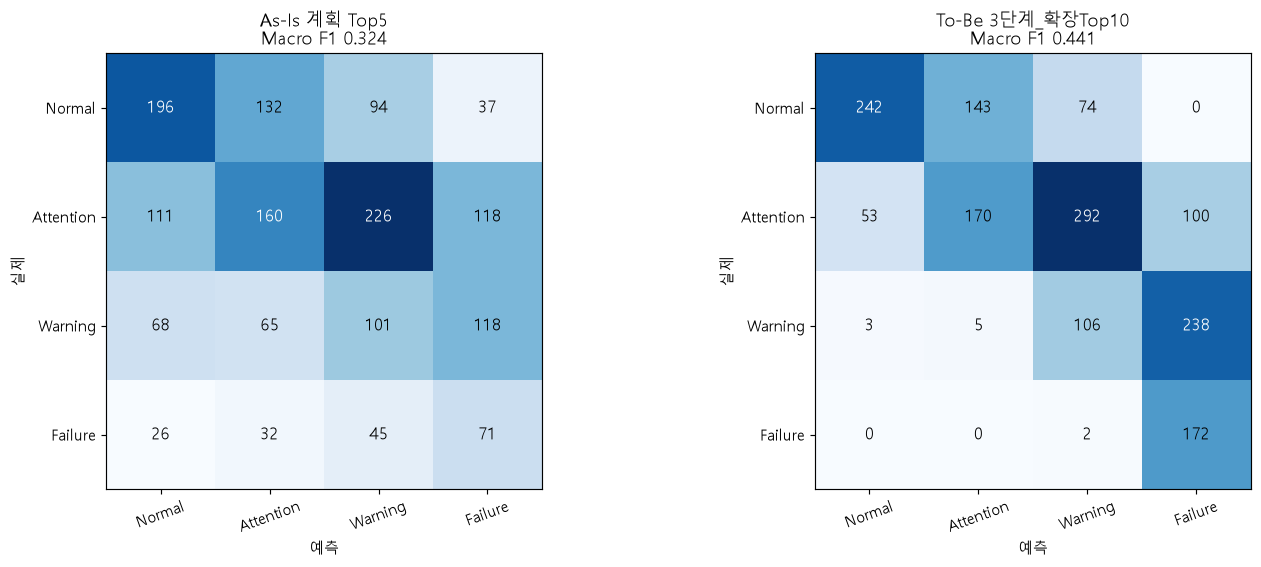

In [61]:
# ============================================================
# 그래프 31. Blind 혼동행렬 비교 (행 = 실제, 열 = 예측)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (title, pred) in zip(axes, [
    ("As-Is 계획 Top5", pred_asis),
    (f"To-Be {best_key}", pred_tobe)
]):
    cm = confusion_matrix(y_blind, pred, labels=range(4))
    ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() * 0.6 else "black", fontsize=11)
    ax.set_xticks(range(4), NAMES, rotation=20)
    ax.set_yticks(range(4), NAMES)
    ax.set_xlabel("예측")
    ax.set_ylabel("실제")
    ax.set_title(f"{title}\nMacro F1 {f1_score(y_blind, pred, average='macro'):.3f}")

show_fig("31_blind_confusion_compare")

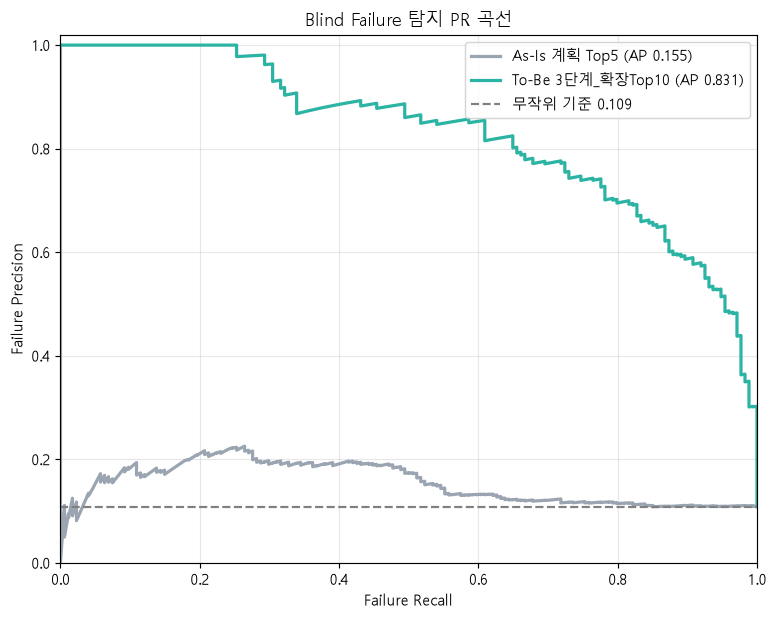

In [62]:
# ============================================================
# 그래프 32. Blind Failure Precision-Recall 곡선 비교
# ============================================================

fig, ax = plt.subplots(figsize=(7.5, 6))

for name, p3, color in [
    ("As-Is 계획 Top5", p3_asis, "#9aa5b1"),
    (f"To-Be {best_key}", p3_tobe, "#2bb3a3")
]:
    prec, rec, _ = precision_recall_curve(y_blind == 3, p3)
    ap = average_precision_score(y_blind == 3, p3)
    ax.plot(rec, prec, color=color, lw=2.2, label=f"{name} (AP {ap:.3f})")

base_rate = (y_blind == 3).mean()
ax.axhline(base_rate, ls="--", color="gray", label=f"무작위 기준 {base_rate:.3f}")
ax.set_xlabel("Failure Recall")
ax.set_ylabel("Failure Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
ax.set_title("Blind Failure 탐지 PR 곡선")
ax.grid(alpha=0.3)

show_fig("32_blind_pr_compare")

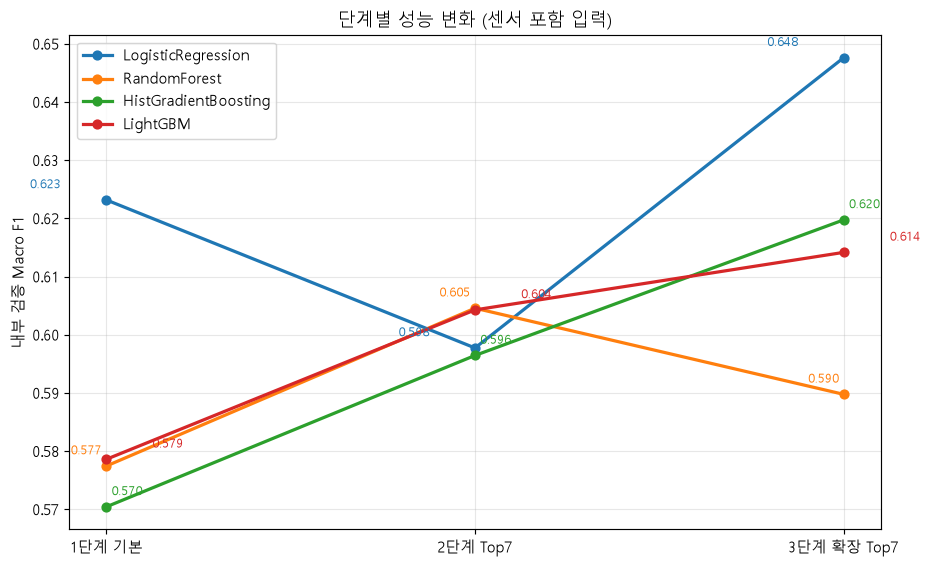

In [63]:
# ============================================================
# 그래프 33. 단계별(1→2→3) 내부 검증 Macro F1 추이
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

for k, alg in enumerate(stage_f1.columns):
    vals = stage_f1[alg].values
    line, = ax.plot(range(len(vals)), vals, marker="o", lw=2.2, label=alg)
    for i, v in enumerate(vals):
        # 알고리즘마다 라벨을 좌우로 엇갈려 겹침 방지
        ax.annotate(f"{v:.3f}", (i, v), textcoords="offset points",
                    xytext=(-42 + 28 * k, 8), ha="center", fontsize=8,
                    color=line.get_color())

ax.set_xticks(range(len(stage_f1.index)), stage_f1.index)
ax.set_ylabel("내부 검증 Macro F1")
ax.set_title("단계별 성능 변화 (센서 포함 입력)")
ax.grid(alpha=0.3)
ax.legend()

show_fig("33_stage_f1_trend")

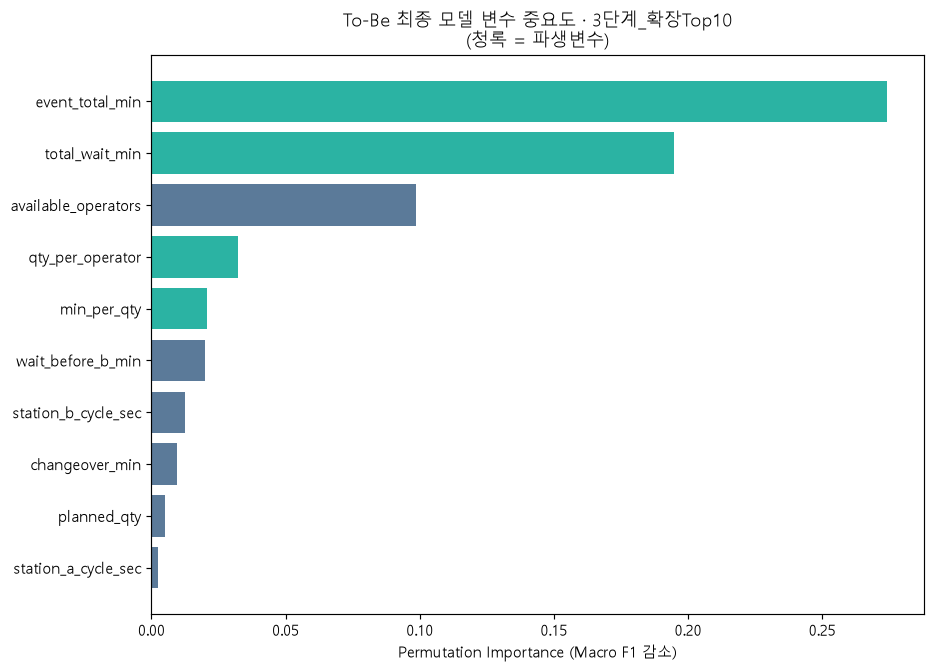

In [64]:
# ============================================================
# 그래프 34. To-Be 최종 모델 Permutation Importance (내부 검증)
# ============================================================

pi = permutation_importance(
    tobe_valid,
    valid_ex[tobe_cols],
    y_valid,
    scoring="f1_macro",
    n_repeats=10,
    random_state=SEED
)

tobe_imp = pd.Series(pi.importances_mean, index=tobe_cols).sort_values()

plt.figure(figsize=(9, 0.5 * len(tobe_imp) + 1.5))
plt.barh(tobe_imp.index, tobe_imp.values,
         color=["#2bb3a3" if c in DERIVED else "#5b7a99" for c in tobe_imp.index])
plt.xlabel("Permutation Importance (Macro F1 감소)")
plt.title(f"To-Be 최종 모델 변수 중요도 · {best_key}\n(청록 = 파생변수)")
show_fig("34_tobe_importance")